In [1]:
import os
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    cohen_kappa_score,
    matthews_corrcoef,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    log_loss
)

from sklearn.preprocessing import label_binarize

warnings.filterwarnings("ignore")

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

PyTorch: 2.14.0+cpu
CUDA available: False
Using device: cpu


In [2]:
# Project root
PROJECT_ROOT = Path.cwd().parent

# DeepDRiD parent directory
DEEPDRID_PARENT = PROJECT_ROOT / "data" / "external" / "deepdrid"

print("Project root:")
print(PROJECT_ROOT)

print("\nDeepDRiD directory:")
print(DEEPDRID_PARENT)

Project root:
d:\downloads\project\Diabetic-Retinopathy-Screening-Project

DeepDRiD directory:
d:\downloads\project\Diabetic-Retinopathy-Screening-Project\data\external\deepdrid


In [3]:
# Find the extracted DeepDRiD folder
deepdrid_candidates = [
    p for p in DEEPDRID_PARENT.iterdir()
    if p.is_dir() and "DeepDRiD" in p.name
]

print("DeepDRiD candidates:")
for p in deepdrid_candidates:
    print(" -", p)

DeepDRiD candidates:
 - d:\downloads\project\Diabetic-Retinopathy-Screening-Project\data\external\deepdrid\deepdrdoc-DeepDRiD-56d8af7


In [4]:
if len(deepdrid_candidates) == 0:
    raise FileNotFoundError(
        "Could not find the extracted DeepDRiD folder."
    )

DEEPDRID_ROOT = deepdrid_candidates[0]

print("Using:")
print(DEEPDRID_ROOT)

Using:
d:\downloads\project\Diabetic-Retinopathy-Screening-Project\data\external\deepdrid\deepdrdoc-DeepDRiD-56d8af7


In [5]:
VALIDATION_ROOT = (
    DEEPDRID_ROOT
    / "regular_fundus_images"
    / "regular-fundus-validation"
)

IMAGE_DIR = VALIDATION_ROOT / "Images"
CSV_PATH = VALIDATION_ROOT / "regular-fundus-validation.csv"

print("Validation directory:")
print(VALIDATION_ROOT)

print("\nImage directory:")
print(IMAGE_DIR)

print("\nCSV:")
print(CSV_PATH)

Validation directory:
d:\downloads\project\Diabetic-Retinopathy-Screening-Project\data\external\deepdrid\deepdrdoc-DeepDRiD-56d8af7\regular_fundus_images\regular-fundus-validation

Image directory:
d:\downloads\project\Diabetic-Retinopathy-Screening-Project\data\external\deepdrid\deepdrdoc-DeepDRiD-56d8af7\regular_fundus_images\regular-fundus-validation\Images

CSV:
d:\downloads\project\Diabetic-Retinopathy-Screening-Project\data\external\deepdrid\deepdrdoc-DeepDRiD-56d8af7\regular_fundus_images\regular-fundus-validation\regular-fundus-validation.csv


In [6]:
print("\nValidation directory exists:", VALIDATION_ROOT.exists())
print("Image directory exists:", IMAGE_DIR.exists())
print("CSV exists:", CSV_PATH.exists())


Validation directory exists: True
Image directory exists: True
CSV exists: True


In [7]:
df = pd.read_csv(CSV_PATH)

print("Shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

Shape: (400, 10)

Columns:
['patient_id', 'image_id', 'image_path', 'Overall quality', 'left_eye_DR_Level', 'right_eye_DR_Level', 'patient_DR_Level', 'Clarity', 'Field definition', 'Artifact']

First 5 rows:


,patient_id,image_id,image_path,Overall quality,left_eye_DR_Level,right_eye_DR_Level,patient_DR_Level,Clarity,Field definition,Artifact
0,265,265_l1,\regular-fundus-validation\265\265_l1.jpg,0,3.0,NaN,4,4,8,10
1,265,265_l2,\regular-fundus-validation\265\265_l2.jpg,0,3.0,NaN,4,6,8,6
2,265,265_r1,\regular-fundus-validation\265\265_r1.jpg,1,NaN,4.0,4,6,8,6
3,265,265_r2,\regular-fundus-validation\265\265_r2.jpg,1,NaN,4.0,4,10,4,0
4,267,267_l1,\regular-fundus-validation\267\267_l1.jpg,1,4.0,NaN,4,10,6,4


In [8]:
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   patient_id          400 non-null    int64  
 1   image_id            400 non-null    str    
 2   image_path          400 non-null    str    
 3   Overall quality     400 non-null    int64  
 4   left_eye_DR_Level   200 non-null    float64
 5   right_eye_DR_Level  200 non-null    float64
 6   patient_DR_Level    400 non-null    int64  
 7   Clarity             400 non-null    int64  
 8   Field definition    400 non-null    int64  
 9   Artifact            400 non-null    int64  
dtypes: float64(2), int64(6), str(2)
memory usage: 31.4 KB
None


In [9]:
for col in df.columns:
    print("\nCOLUMN:", col)
    print(df[col].head(10).tolist())


COLUMN: patient_id
[265, 265, 265, 265, 267, 267, 267, 267, 277, 277]

COLUMN: image_id
['265_l1', '265_l2', '265_r1', '265_r2', '267_l1', '267_l2', '267_r1', '267_r2', '277_l1', '277_l2']

COLUMN: image_path
['\\regular-fundus-validation\\265\\265_l1.jpg', '\\regular-fundus-validation\\265\\265_l2.jpg', '\\regular-fundus-validation\\265\\265_r1.jpg', '\\regular-fundus-validation\\265\\265_r2.jpg', '\\regular-fundus-validation\\267\\267_l1.jpg', '\\regular-fundus-validation\\267\\267_l2.jpg', '\\regular-fundus-validation\\267\\267_r1.jpg', '\\regular-fundus-validation\\267\\267_r2.jpg', '\\regular-fundus-validation\\277\\277_l1.jpg', '\\regular-fundus-validation\\277\\277_l2.jpg']

COLUMN: Overall quality
[0, 0, 1, 1, 1, 1, 1, 1, 1, 1]

COLUMN: left_eye_DR_Level
[3.0, 3.0, nan, nan, 4.0, 4.0, nan, nan, 2.0, 2.0]

COLUMN: right_eye_DR_Level
[nan, nan, 4.0, 4.0, nan, nan, 3.0, 3.0, nan, nan]

COLUMN: patient_DR_Level
[4, 4, 4, 4, 4, 4, 4, 4, 4, 4]

COLUMN: Clarity
[4, 6, 6, 10, 10, 8, 6

In [10]:
# Try to identify image column
image_candidates = [
    c for c in df.columns
    if any(x in c.lower() for x in ["image", "img", "path", "file"])
]

# Try to identify DR label column
label_candidates = [
    c for c in df.columns
    if any(x in c.lower() for x in ["dr", "grade", "label"])
]

print("Possible image columns:", image_candidates)
print("Possible label columns:", label_candidates)

Possible image columns: ['image_id', 'image_path']
Possible label columns: ['left_eye_DR_Level', 'right_eye_DR_Level', 'patient_DR_Level']


In [12]:
IMAGE_COL = "image_id"

print("Image column:", IMAGE_COL)

print("\nAvailable label columns:")
print([
    "left_eye_DR_Level",
    "right_eye_DR_Level",
    "patient_DR_level"
])

Image column: image_id

Available label columns:
['left_eye_DR_Level', 'right_eye_DR_Level', 'patient_DR_level']


In [14]:
print("EXACT CSV COLUMNS:")
for i, col in enumerate(df.columns):
    print(i, repr(col))

EXACT CSV COLUMNS:
0 'patient_id'
1 'image_id'
2 'image_path'
3 'Overall quality'
4 'left_eye_DR_Level'
5 'right_eye_DR_Level'
6 'patient_DR_Level'
7 'Clarity'
8 'Field definition'
9 'Artifact'


In [15]:
print("\nDATAFRAME SHAPE:")
print(df.shape)

print("\nFIRST 5 ROWS:")
display(df.head())


DATAFRAME SHAPE:
(400, 10)

FIRST 5 ROWS:


,patient_id,image_id,image_path,Overall quality,left_eye_DR_Level,right_eye_DR_Level,patient_DR_Level,Clarity,Field definition,Artifact
0,265,265_l1,\regular-fundus-validation\265\265_l1.jpg,0,3.0,NaN,4,4,8,10
1,265,265_l2,\regular-fundus-validation\265\265_l2.jpg,0,3.0,NaN,4,6,8,6
2,265,265_r1,\regular-fundus-validation\265\265_r1.jpg,1,NaN,4.0,4,6,8,6
3,265,265_r2,\regular-fundus-validation\265\265_r2.jpg,1,NaN,4.0,4,10,4,0
4,267,267_l1,\regular-fundus-validation\267\267_l1.jpg,1,4.0,NaN,4,10,6,4


In [16]:
print("\nALL COLUMN NAMES:")
print(df.columns.tolist())


ALL COLUMN NAMES:
['patient_id', 'image_id', 'image_path', 'Overall quality', 'left_eye_DR_Level', 'right_eye_DR_Level', 'patient_DR_Level', 'Clarity', 'Field definition', 'Artifact']


In [17]:
IMAGE_COL = "image_id"

print("Image column:", IMAGE_COL)

Image column: image_id


In [18]:
def get_eye_label(row):
    image_id = str(row["image_id"]).lower()

    if "_l" in image_id:
        return row["left_eye_DR_Level"]

    elif "_r" in image_id:
        return row["right_eye_DR_Level"]

    else:
        return np.nan


df["DR_Level"] = df.apply(get_eye_label, axis=1)

print("Created per-image DR label.")
print(df[[
    "image_id",
    "left_eye_DR_Level",
    "right_eye_DR_Level",
    "patient_DR_Level",
    "DR_Level"
]].head(20))

Created per-image DR label.
   image_id  left_eye_DR_Level  right_eye_DR_Level  patient_DR_Level  DR_Level
0    265_l1                3.0                 NaN                 4       3.0
1    265_l2                3.0                 NaN                 4       3.0
2    265_r1                NaN                 4.0                 4       4.0
3    265_r2                NaN                 4.0                 4       4.0
4    267_l1                4.0                 NaN                 4       4.0
5    267_l2                4.0                 NaN                 4       4.0
6    267_r1                NaN                 3.0                 4       3.0
7    267_r2                NaN                 3.0                 4       3.0
8    277_l1                2.0                 NaN                 4       2.0
9    277_l2                2.0                 NaN                 4       2.0
10   277_r1                NaN                 4.0                 4       4.0
11   277_r2             

In [19]:
missing_labels = df["DR_Level"].isna()

print("Total images:", len(df))
print("Missing DR labels:", missing_labels.sum())

Total images: 400
Missing DR labels: 0


In [20]:
df["DR_Level"] = df["DR_Level"].astype(int)

print("DR label distribution:")
print(
    df["DR_Level"]
    .value_counts()
    .sort_index()
)

DR label distribution:
DR_Level
0    174
1     46
2     92
3     68
4     20
Name: count, dtype: int64


In [21]:
class_names = [
    "No DR",
    "Mild",
    "Moderate",
    "Severe",
    "PDR"
]

for label, name in enumerate(class_names):
    count = (df["DR_Level"] == label).sum()
    print(f"{label} - {name}: {count}")

0 - No DR: 174
1 - Mild: 46
2 - Moderate: 92
3 - Severe: 68
4 - PDR: 20


In [22]:
print("Example image paths from CSV:")

display(
    df[
        ["image_id", "image_path", "DR_Level"]
    ].head(10)
)

Example image paths from CSV:


,image_id,image_path,DR_Level
0,265_l1,\regular-fundus-validation\265\265_l1.jpg,3
1,265_l2,\regular-fundus-validation\265\265_l2.jpg,3
2,265_r1,\regular-fundus-validation\265\265_r1.jpg,4
3,265_r2,\regular-fundus-validation\265\265_r2.jpg,4
4,267_l1,\regular-fundus-validation\267\267_l1.jpg,4
5,267_l2,\regular-fundus-validation\267\267_l2.jpg,4
6,267_r1,\regular-fundus-validation\267\267_r1.jpg,3
7,267_r2,\regular-fundus-validation\267\267_r2.jpg,3
8,277_l1,\regular-fundus-validation\277\277_l1.jpg,2
9,277_l2,\regular-fundus-validation\277\277_l2.jpg,2


In [23]:
def resolve_deepdrid_path(row, image_dir):

    image_id = str(row["image_id"])

    # Search recursively using the image filename
    possible_extensions = [
        "",
        ".jpg",
        ".jpeg",
        ".JPG",
        ".JPEG"
    ]

    for ext in possible_extensions:

        filename = image_id + ext

        matches = list(
            image_dir.rglob(filename)
        )

        if matches:
            return matches[0]

    return None


df["resolved_path"] = df.apply(
    lambda row: resolve_deepdrid_path(
        row,
        IMAGE_DIR
    ),
    axis=1
)

print(
    "Images found:",
    df["resolved_path"].notna().sum()
)

print(
    "Images missing:",
    df["resolved_path"].isna().sum()
)

Images found: 400
Images missing: 0


In [24]:
print("=" * 60)
print("DeepDRiD Validation Dataset")
print("=" * 60)

print("Total images:", len(df))
print("Images found:", df["resolved_path"].notna().sum())
print("Missing images:", df["resolved_path"].isna().sum())
print()

print("Class distribution:")

for label, name in enumerate(class_names):

    count = (
        df["DR_Level"] == label
    ).sum()

    print(
        f"{label} - {name:<10}: {count}"
    )

DeepDRiD Validation Dataset
Total images: 400
Images found: 400
Missing images: 0

Class distribution:
0 - No DR     : 174
1 - Mild      : 46
2 - Moderate  : 92
3 - Severe    : 68
4 - PDR       : 20


In [25]:
class DeepDRiDDataset(Dataset):

    def __init__(
        self,
        dataframe,
        transform=None
    ):

        self.df = dataframe.reset_index(
            drop=True
        )

        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):

        row = self.df.iloc[idx]

        image_path = row["resolved_path"]

        label = int(
            row["DR_Level"]
        )

        image = Image.open(
            image_path
        ).convert("RGB")

        if self.transform:
            image = self.transform(image)

        return (
            image,
            label,
            str(image_path)
        )

In [27]:
# Evaluation transform used by the project models

eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("Evaluation transform created successfully.")

Evaluation transform created successfully.


In [28]:
deepdrid_dataset = DeepDRiDDataset(
    df,
    transform=eval_transform
)

deepdrid_loader = DataLoader(
    deepdrid_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

print("Dataset size:", len(deepdrid_dataset))
print("Number of batches:", len(deepdrid_loader))

Dataset size: 400
Number of batches: 13


In [29]:
image, label, path = deepdrid_dataset[0]

print("Image path:", path)
print("Label:", label)
print("Tensor shape:", image.shape)

Image path: d:\downloads\project\Diabetic-Retinopathy-Screening-Project\data\external\deepdrid\deepdrdoc-DeepDRiD-56d8af7\regular_fundus_images\regular-fundus-validation\Images\265\265_l1.jpg
Label: 3
Tensor shape: torch.Size([3, 224, 224])


In [30]:
import torch
import torch.nn as nn
from torchvision import models

import numpy as np
import pandas as pd
from pathlib import Path

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    cohen_kappa_score,
    matthews_corrcoef,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    log_loss
)

from sklearn.preprocessing import label_binarize

import matplotlib.pyplot as plt
import seaborn as sns

In [31]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Device: cpu


In [32]:
def build_resnet18(num_classes=5):

    model = models.resnet18(weights=None)

    model.fc = nn.Linear(
        model.fc.in_features,
        num_classes
    )

    return model

In [33]:
resnet_candidates = list(
    PROJECT_ROOT.rglob(
        "best_resnet18_weighted_extended.pth"
    )
)

print("ResNet checkpoints found:")

for p in resnet_candidates:
    print(p)

ResNet checkpoints found:
d:\downloads\project\Diabetic-Retinopathy-Screening-Project\models\best_resnet18_weighted_extended.pth
d:\downloads\project\Diabetic-Retinopathy-Screening-Project\temp_checkpoints\best_resnet18_weighted_extended.pth


In [34]:
if len(resnet_candidates) == 0:
    raise FileNotFoundError(
        "best_resnet18_weighted_extended.pth was not found."
    )

RESNET_CHECKPOINT = resnet_candidates[0]

print("\nUsing:")
print(RESNET_CHECKPOINT)


Using:
d:\downloads\project\Diabetic-Retinopathy-Screening-Project\models\best_resnet18_weighted_extended.pth


In [36]:
from pathlib import Path

RESNET_CHECKPOINT = Path(
    r"D:\downloads\project\Diabetic-Retinopathy-Screening-Project\temp_checkpoints\best_resnet18_weighted_extended.pth"
)

print("Checkpoint exists:", RESNET_CHECKPOINT.exists())
print("Is file:", RESNET_CHECKPOINT.is_file())
print("Path:", RESNET_CHECKPOINT)

Checkpoint exists: True
Is file: True
Path: D:\downloads\project\Diabetic-Retinopathy-Screening-Project\temp_checkpoints\best_resnet18_weighted_extended.pth


In [38]:
from pathlib import Path

project_root = Path(
    r"D:\downloads\project\Diabetic-Retinopathy-Screening-Project"
)

for p in project_root.rglob("best_resnet18_weighted_extended.pth"):
    print(p)
    print("FILE:", p.is_file())

D:\downloads\project\Diabetic-Retinopathy-Screening-Project\models\best_resnet18_weighted_extended.pth
FILE: False
D:\downloads\project\Diabetic-Retinopathy-Screening-Project\temp_checkpoints\best_resnet18_weighted_extended.pth
FILE: True


In [40]:
resnet_model = build_resnet18(num_classes=5)

resnet_checkpoint = torch.load(
    RESNET_CHECKPOINT,
    map_location=device,
    weights_only=False
)

print("Checkpoint keys:", resnet_checkpoint.keys())

Checkpoint keys: dict_keys(['epoch', 'model_state_dict', 'optimizer_state_dict', 'scheduler_state_dict', 'val_loss', 'val_accuracy', 'val_qwk', 'history', 'class_weights'])


In [41]:
resnet_model.load_state_dict(
    resnet_checkpoint["model_state_dict"]
)

resnet_model = resnet_model.to(device)
resnet_model.eval()

print("✅ ResNet checkpoint loaded successfully")

✅ ResNet checkpoint loaded successfully


In [42]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
from torch.utils.data import DataLoader

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    cohen_kappa_score,
    matthews_corrcoef,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    log_loss
)

from sklearn.preprocessing import label_binarize
from pathlib import Path
from tqdm.auto import tqdm

print("Imports successful")

Imports successful


In [44]:
print("Number of images:", len(df))
print("\nLabel distribution:")
print(df["DR_Level"].value_counts().sort_index())

print("\nDataLoader batches:", len(deepdrid_loader))

Number of images: 400

Label distribution:
DR_Level
0    174
1     46
2     92
3     68
4     20
Name: count, dtype: int64

DataLoader batches: 13


In [45]:
CLASS_NAMES = [
    "No DR",
    "Mild",
    "Moderate",
    "Severe",
    "Proliferative DR"
]

NUM_CLASSES = 5

print(CLASS_NAMES)

['No DR', 'Mild', 'Moderate', 'Severe', 'Proliferative DR']


In [46]:
# ---------------------------------------------------------
# Build Joint Attention Fusion architecture
# ---------------------------------------------------------

resnet_raw = models.resnet18(weights=None)

# 5-class head
resnet_raw.fc = nn.Linear(
    resnet_raw.fc.in_features,
    NUM_CLASSES
)

effnet_raw = models.efficientnet_b0(weights=None)

# 5-class head
effnet_raw.classifier[1] = nn.Linear(
    effnet_raw.classifier[1].in_features,
    NUM_CLASSES
)

# Feature extractors
res_features = nn.Sequential(
    *list(resnet_raw.children())[:-1]
)

eff_features = effnet_raw.features

eff_pool = nn.AdaptiveAvgPool2d((1, 1))


class JointAttentionFusionModel(nn.Module):

    def __init__(
        self,
        resnet_features,
        efficientnet_features,
        efficientnet_pool,
        num_classes=5
    ):
        super().__init__()

        self.resnet_features = resnet_features
        self.efficientnet_features = efficientnet_features
        self.efficientnet_pool = efficientnet_pool

        self.resnet_projection = nn.Sequential(
            nn.Linear(512, 256),
            nn.ReLU(),
            nn.BatchNorm1d(256)
        )

        self.efficientnet_projection = nn.Sequential(
            nn.Linear(1280, 256),
            nn.ReLU(),
            nn.BatchNorm1d(256)
        )

        self.attention = nn.Sequential(
            nn.Linear(512, 128),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(128, 2)
        )

        self.classifier = nn.Sequential(
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(0.4),

            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Dropout(0.3),

            nn.Linear(64, num_classes)
        )

    def forward(self, x):

        # ResNet branch
        r_feat = self.resnet_features(x)
        r_feat = torch.flatten(r_feat, 1)

        r_proj = self.resnet_projection(r_feat)

        # EfficientNet branch
        e_feat = self.efficientnet_features(x)
        e_feat = self.efficientnet_pool(e_feat)
        e_feat = torch.flatten(e_feat, 1)

        e_proj = self.efficientnet_projection(e_feat)

        # Combine branch representations
        combined = torch.cat(
            [r_proj, e_proj],
            dim=1
        )

        # Attention weights
        attn_logits = self.attention(combined)

        attn_weights = torch.softmax(
            attn_logits,
            dim=1
        )

        # Weighted fusion
        fused = (
            attn_weights[:, 0:1] * r_proj
            +
            attn_weights[:, 1:2] * e_proj
        )

        # Final classifier
        out = self.classifier(fused)

        return out, attn_weights

In [47]:
joint_model = JointAttentionFusionModel(
    resnet_features=res_features,
    efficientnet_features=eff_features,
    efficientnet_pool=eff_pool,
    num_classes=NUM_CLASSES
)

joint_model = joint_model.to(device)

print("Joint model created successfully")

Joint model created successfully


In [48]:
BEST_JOINT_CHECKPOINT = Path(
    r"D:\downloads\project\Diabetic-Retinopathy-Screening-Project\temp_checkpoints\best_joint_finetuned_attention_fusion.pth"
)

LAST_JOINT_CHECKPOINT = Path(
    r"D:\downloads\project\Diabetic-Retinopathy-Screening-Project\temp_checkpoints\last_joint_finetuned_attention_fusion.pth"
)

print("Best checkpoint exists:",
      BEST_JOINT_CHECKPOINT.is_file())

print("Last checkpoint exists:",
      LAST_JOINT_CHECKPOINT.is_file())

Best checkpoint exists: True
Last checkpoint exists: True


In [49]:
best_joint_checkpoint = torch.load(
    BEST_JOINT_CHECKPOINT,
    map_location=device,
    weights_only=False
)

print("Best Joint checkpoint keys:")
print(best_joint_checkpoint.keys())

Best Joint checkpoint keys:
dict_keys(['epoch', 'model_state_dict', 'optimizer_state_dict', 'scheduler_state_dict', 'scaler_state_dict', 'history', 'best_val_qwk', 'best_val_loss', 'epochs_no_improve', 'val_loss', 'val_accuracy', 'val_macro_f1', 'val_qwk'])


In [50]:
joint_model.load_state_dict(
    best_joint_checkpoint["model_state_dict"]
)

joint_model = joint_model.to(device)
joint_model.eval()

print("✅ Best Joint checkpoint loaded successfully")

✅ Best Joint checkpoint loaded successfully


In [51]:
images, labels, paths = next(iter(deepdrid_loader))

images = images.to(device)

with torch.no_grad():

    outputs, attention = joint_model(images)

    predictions = torch.argmax(
        outputs,
        dim=1
    )

print("Input shape:", images.shape)
print("Output shape:", outputs.shape)
print("Prediction shape:", predictions.shape)
print("Attention shape:", attention.shape)

print("\nFirst 10 predictions:")
print(predictions[:10].cpu().numpy())

print("\nFirst 10 actual labels:")
print(labels[:10].numpy())

print("\nFirst 10 attention weights:")
print(attention[:10].cpu().numpy())

Input shape: torch.Size([32, 3, 224, 224])
Output shape: torch.Size([32, 5])
Prediction shape: torch.Size([32])
Attention shape: torch.Size([32, 2])

First 10 predictions:
[3 3 4 4 4 4 4 4 4 3]

First 10 actual labels:
[3 3 4 4 4 4 3 3 2 2]

First 10 attention weights:
[[0.75785327 0.24214675]
 [0.79178584 0.20821422]
 [0.8084397  0.19156028]
 [0.8437062  0.15629384]
 [0.9699943  0.03000569]
 [0.95650256 0.0434974 ]
 [0.9662252  0.03377482]
 [0.96496284 0.03503716]
 [0.70581603 0.29418394]
 [0.75283533 0.24716459]]


In [52]:
def run_resnet_inference(model, loader, device):

    model.eval()

    all_labels = []
    all_predictions = []
    all_probabilities = []
    all_paths = []

    with torch.no_grad():

        for images, labels, paths in tqdm(
            loader,
            desc="ResNet inference"
        ):

            images = images.to(device)

            logits = model(images)

            probabilities = torch.softmax(
                logits,
                dim=1
            )

            predictions = torch.argmax(
                logits,
                dim=1
            )

            all_labels.extend(
                labels.cpu().numpy()
            )

            all_predictions.extend(
                predictions.cpu().numpy()
            )

            all_probabilities.append(
                probabilities.cpu().numpy()
            )

            all_paths.extend(paths)

    all_probabilities = np.concatenate(
        all_probabilities,
        axis=0
    )

    return (
        np.array(all_labels),
        np.array(all_predictions),
        all_probabilities,
        all_paths
    )

In [53]:
def run_joint_inference(model, loader, device):

    model.eval()

    all_labels = []
    all_predictions = []
    all_probabilities = []
    all_attention = []
    all_paths = []

    with torch.no_grad():

        for images, labels, paths in tqdm(
            loader,
            desc="Joint inference"
        ):

            images = images.to(device)

            logits, attention = model(images)

            probabilities = torch.softmax(
                logits,
                dim=1
            )

            predictions = torch.argmax(
                logits,
                dim=1
            )

            all_labels.extend(
                labels.cpu().numpy()
            )

            all_predictions.extend(
                predictions.cpu().numpy()
            )

            all_probabilities.append(
                probabilities.cpu().numpy()
            )

            all_attention.append(
                attention.cpu().numpy()
            )

            all_paths.extend(paths)

    all_probabilities = np.concatenate(
        all_probabilities,
        axis=0
    )

    all_attention = np.concatenate(
        all_attention,
        axis=0
    )

    return (
        np.array(all_labels),
        np.array(all_predictions),
        all_probabilities,
        all_attention,
        all_paths
    )

In [54]:
print("Starting ResNet evaluation...")

(
    y_true_resnet,
    y_pred_resnet,
    y_prob_resnet,
    paths_resnet
) = run_resnet_inference(
    resnet_model,
    deepdrid_loader,
    device
)

print("\n✅ ResNet evaluation completed")

print("Images evaluated:", len(y_true_resnet))

Starting ResNet evaluation...


ResNet inference: 100%|██████████| 13/13 [00:52<00:00,  4.06s/it]


✅ ResNet evaluation completed
Images evaluated: 400


In [55]:
print("Starting Best Joint evaluation...")

(
    y_true_joint,
    y_pred_joint,
    y_prob_joint,
    attention_joint,
    paths_joint
) = run_joint_inference(
    joint_model,
    deepdrid_loader,
    device
)

print("\n✅ Best Joint evaluation completed")

print("Images evaluated:", len(y_true_joint))

Starting Best Joint evaluation...


Joint inference: 100%|██████████| 13/13 [00:44<00:00,  3.45s/it]


✅ Best Joint evaluation completed
Images evaluated: 400


In [56]:
def calculate_metrics(
    y_true,
    y_pred,
    y_prob
):

    results = {}

    results["Accuracy"] = accuracy_score(
        y_true,
        y_pred
    )

    results["Balanced Accuracy"] = balanced_accuracy_score(
        y_true,
        y_pred
    )

    results["Macro Precision"] = precision_score(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )

    results["Macro Recall"] = recall_score(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )

    results["Macro F1"] = f1_score(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )

    results["Weighted F1"] = f1_score(
        y_true,
        y_pred,
        average="weighted",
        zero_division=0
    )

    # Quadratic Weighted Kappa
    results["QWK"] = cohen_kappa_score(
        y_true,
        y_pred,
        weights="quadratic"
    )

    # Cohen's Kappa
    results["Cohen Kappa"] = cohen_kappa_score(
        y_true,
        y_pred
    )

    # MCC
    results["MCC"] = matthews_corrcoef(
        y_true,
        y_pred
    )

    # Log loss
    results["Log Loss"] = log_loss(
        y_true,
        y_prob,
        labels=list(range(NUM_CLASSES))
    )

    # ROC-AUC
    try:

        results["ROC-AUC"] = roc_auc_score(
            y_true,
            y_prob,
            multi_class="ovr",
            average="macro",
            labels=list(range(NUM_CLASSES))
        )

    except ValueError:

        results["ROC-AUC"] = np.nan

    return results

In [57]:
resnet_metrics = calculate_metrics(
    y_true_resnet,
    y_pred_resnet,
    y_prob_resnet
)

print("\n========== WEIGHTED RESNET-18 ==========")

for metric, value in resnet_metrics.items():

    print(
        f"{metric:20s}: {value:.4f}"
        if not pd.isna(value)
        else f"{metric:20s}: NaN"
    )


========== WEIGHTED RESNET-18 ==========
Accuracy            : 0.5525
Balanced Accuracy   : 0.4740
Macro Precision     : 0.4687
Macro Recall        : 0.4740
Macro F1            : 0.4563
Weighted F1         : 0.5523
QWK                 : 0.7547
Cohen Kappa         : 0.3789
MCC                 : 0.3830
Log Loss            : 1.6928
ROC-AUC             : 0.8242


In [58]:
joint_metrics = calculate_metrics(
    y_true_joint,
    y_pred_joint,
    y_prob_joint
)

print("\n========== BEST JOINT ATTENTION FUSION ==========")

for metric, value in joint_metrics.items():

    print(
        f"{metric:20s}: {value:.4f}"
        if not pd.isna(value)
        else f"{metric:20s}: NaN"
    )


========== BEST JOINT ATTENTION FUSION ==========
Accuracy            : 0.5925
Balanced Accuracy   : 0.5232
Macro Precision     : 0.4938
Macro Recall        : 0.5232
Macro F1            : 0.5017
Weighted F1         : 0.6003
QWK                 : 0.7894
Cohen Kappa         : 0.4407
MCC                 : 0.4418
Log Loss            : 1.0575
ROC-AUC             : 0.8349


In [59]:
comparison = pd.DataFrame({
    "Metric": list(resnet_metrics.keys()),
    "Weighted ResNet-18": list(resnet_metrics.values()),
    "Best Joint Attention": list(joint_metrics.values())
})

comparison

,Metric,Weighted ResNet-18,Best Joint Attention
0,Accuracy,0.552500,0.592500
1,Balanced Accuracy,0.473994,0.523216
2,Macro Precision,0.468651,0.493788
3,Macro Recall,0.473994,0.523216
4,Macro F1,0.456269,0.501692
5,Weighted F1,0.552260,0.600308
6,QWK,0.754717,0.789367
7,Cohen Kappa,0.378871,0.440699
8,MCC,0.382981,0.441833
9,Log Loss,1.692751,1.057505


In [60]:
print(
    classification_report(
        y_true_resnet,
        y_pred_resnet,
        labels=list(range(NUM_CLASSES)),
        target_names=CLASS_NAMES,
        zero_division=0
    )
)


                  precision    recall  f1-score   support

           No DR       0.74      0.68      0.71       174
            Mild       0.21      0.20      0.20        46
        Moderate       0.47      0.65      0.55        92
          Severe       0.61      0.34      0.43        68
Proliferative DR       0.31      0.50      0.38        20

        accuracy                           0.55       400
       macro avg       0.47      0.47      0.46       400
    weighted avg       0.57      0.55      0.55       400



In [61]:
print(
    classification_report(
        y_true_joint,
        y_pred_joint,
        labels=list(range(NUM_CLASSES)),
        target_names=CLASS_NAMES,
        zero_division=0
    )
)

                  precision    recall  f1-score   support

           No DR       0.80      0.72      0.76       174
            Mild       0.32      0.30      0.31        46
        Moderate       0.53      0.54      0.53        92
          Severe       0.54      0.54      0.54        68
Proliferative DR       0.28      0.50      0.36        20

        accuracy                           0.59       400
       macro avg       0.49      0.52      0.50       400
    weighted avg       0.61      0.59      0.60       400



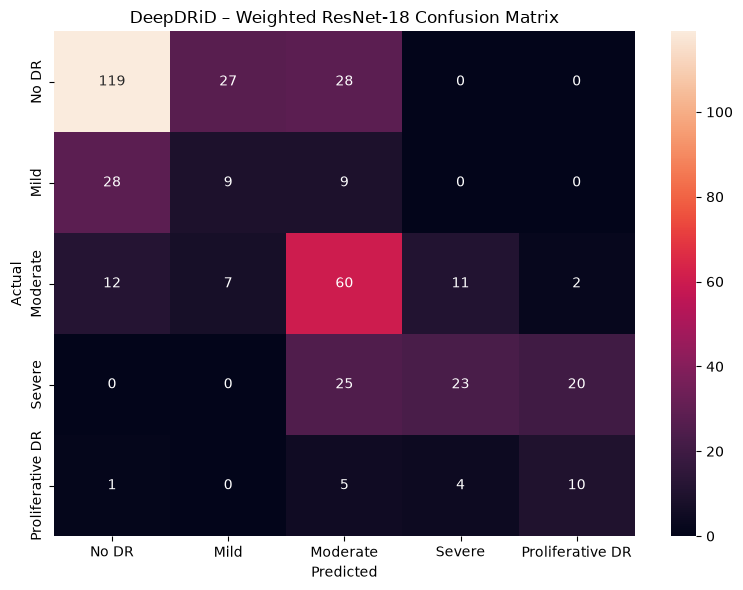

In [62]:
cm_resnet = confusion_matrix(
    y_true_resnet,
    y_pred_resnet,
    labels=list(range(NUM_CLASSES))
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm_resnet,
    annot=True,
    fmt="d",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("DeepDRiD – Weighted ResNet-18 Confusion Matrix")

plt.tight_layout()
plt.show()

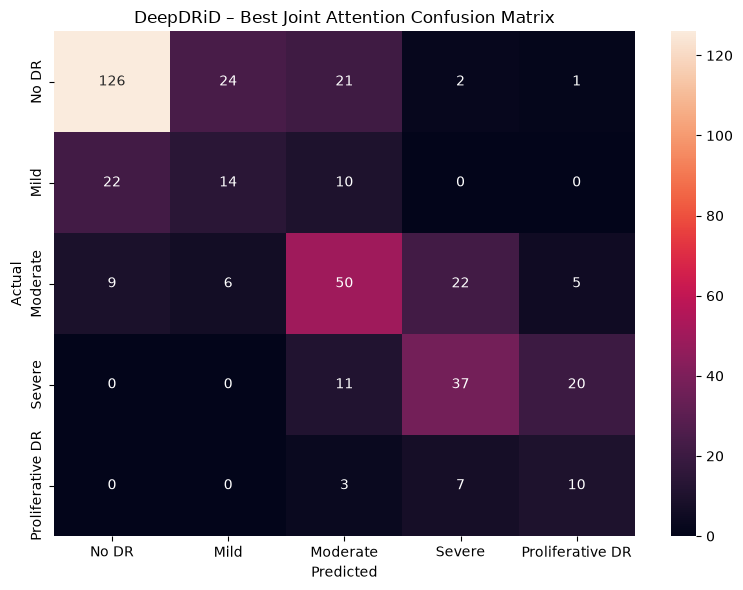

In [63]:
cm_joint = confusion_matrix(
    y_true_joint,
    y_pred_joint,
    labels=list(range(NUM_CLASSES))
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm_joint,
    annot=True,
    fmt="d",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("DeepDRiD – Best Joint Attention Confusion Matrix")

plt.tight_layout()
plt.show()

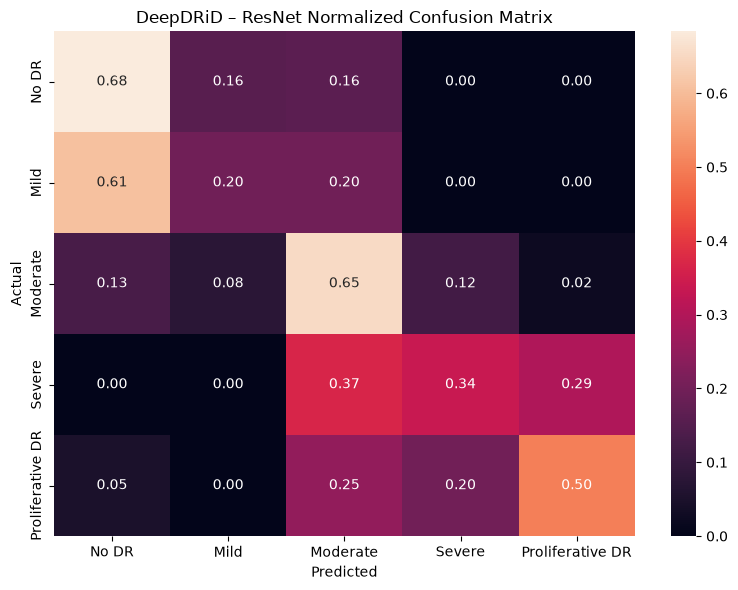

In [64]:
cm_resnet_norm = cm_resnet.astype(float) / np.maximum(
    cm_resnet.sum(axis=1, keepdims=True),
    1
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm_resnet_norm,
    annot=True,
    fmt=".2f",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("DeepDRiD – ResNet Normalized Confusion Matrix")

plt.tight_layout()
plt.show()

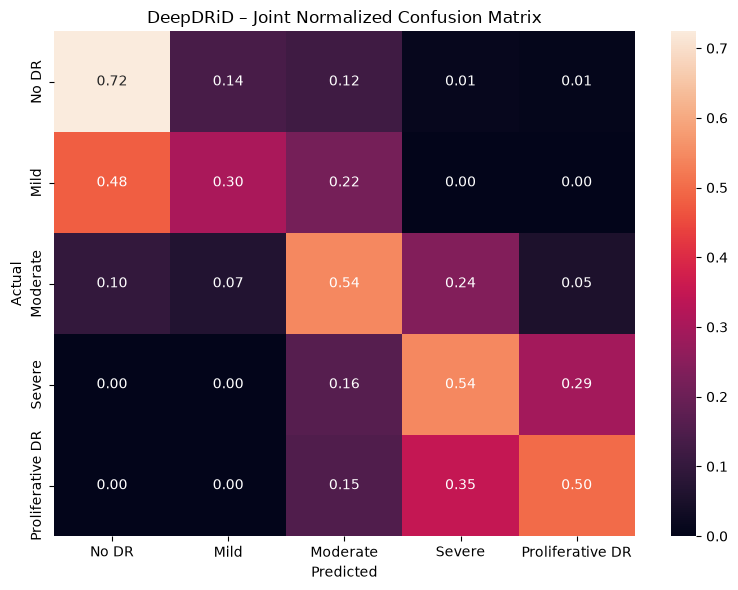

In [65]:
cm_joint_norm = cm_joint.astype(float) / np.maximum(
    cm_joint.sum(axis=1, keepdims=True),
    1
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm_joint_norm,
    annot=True,
    fmt=".2f",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("DeepDRiD – Joint Normalized Confusion Matrix")

plt.tight_layout()
plt.show()

In [66]:
attention_df = pd.DataFrame(
    attention_joint,
    columns=[
        "ResNet_Attention",
        "EfficientNet_Attention"
    ]
)

print(attention_df.describe())

       ResNet_Attention  EfficientNet_Attention
count        400.000000              400.000000
mean           0.645885                0.354115
std            0.146995                0.146995
min            0.257182                0.019344
25%            0.563352                0.261636
50%            0.649873                0.350127
75%            0.738364                0.436648
max            0.980656                0.742818


In [67]:
print(
    "\nMean ResNet attention:",
    attention_df["ResNet_Attention"].mean()
)

print(
    "Mean EfficientNet attention:",
    attention_df["EfficientNet_Attention"].mean()
)


Mean ResNet attention: 0.6458846
Mean EfficientNet attention: 0.3541154


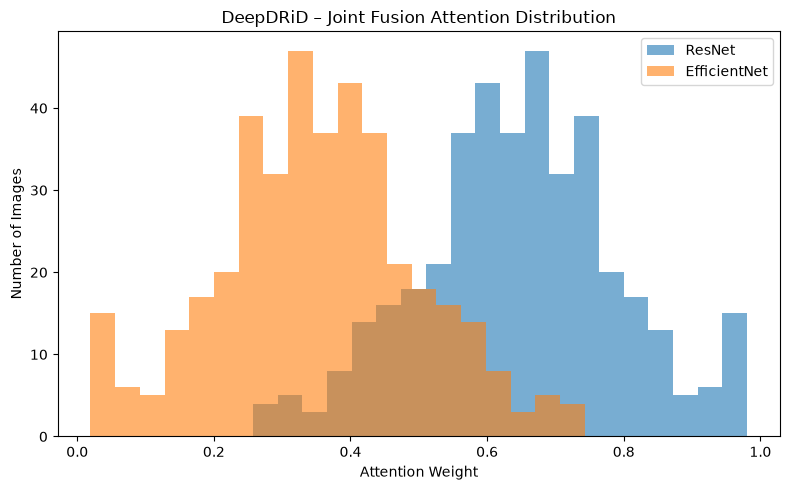

In [68]:
plt.figure(figsize=(8, 5))

plt.hist(
    attention_df["ResNet_Attention"],
    bins=20,
    alpha=0.6,
    label="ResNet"
)

plt.hist(
    attention_df["EfficientNet_Attention"],
    bins=20,
    alpha=0.6,
    label="EfficientNet"
)

plt.xlabel("Attention Weight")
plt.ylabel("Number of Images")
plt.title("DeepDRiD – Joint Fusion Attention Distribution")
plt.legend()

plt.tight_layout()
plt.show()

In [69]:
results_df = pd.DataFrame({

    "image_path": paths_resnet,

    "actual": y_true_resnet,

    "actual_label": [
        CLASS_NAMES[x]
        for x in y_true_resnet
    ],

    "resnet_prediction": y_pred_resnet,

    "resnet_prediction_label": [
        CLASS_NAMES[x]
        for x in y_pred_resnet
    ],

    "joint_prediction": y_pred_joint,

    "joint_prediction_label": [
        CLASS_NAMES[x]
        for x in y_pred_joint
    ],

    "resnet_correct": (
        y_true_resnet == y_pred_resnet
    ),

    "joint_correct": (
        y_true_joint == y_pred_joint
    ),

    "resnet_attention": attention_joint[:, 0],

    "efficientnet_attention": attention_joint[:, 1]
})

results_df.head()

,image_path,actual,actual_label,resnet_prediction,resnet_prediction_label,joint_prediction,joint_prediction_label,resnet_correct,joint_correct,resnet_attention,efficientnet_attention
0,d:\downloads\project\Diabetic-Retinopathy-Scre...,3,Severe,3,Severe,3,Severe,True,True,0.757853,0.242147
1,d:\downloads\project\Diabetic-Retinopathy-Scre...,3,Severe,3,Severe,3,Severe,True,True,0.791786,0.208214
2,d:\downloads\project\Diabetic-Retinopathy-Scre...,4,Proliferative DR,4,Proliferative DR,4,Proliferative DR,True,True,0.808440,0.191560
3,d:\downloads\project\Diabetic-Retinopathy-Scre...,4,Proliferative DR,4,Proliferative DR,4,Proliferative DR,True,True,0.843706,0.156294
4,d:\downloads\project\Diabetic-Retinopathy-Scre...,4,Proliferative DR,4,Proliferative DR,4,Proliferative DR,True,True,0.969994,0.030006


In [70]:
joint_better = results_df[
    (results_df["resnet_correct"] == False) &
    (results_df["joint_correct"] == True)
]

print(
    "Cases where Joint is correct and ResNet is wrong:",
    len(joint_better)
)

joint_better.head(20)

Cases where Joint is correct and ResNet is wrong: 39


,image_path,actual,actual_label,resnet_prediction,resnet_prediction_label,joint_prediction,joint_prediction_label,resnet_correct,joint_correct,resnet_attention,efficientnet_attention
18,d:\downloads\project\Diabetic-Retinopathy-Scre...,3,Severe,2,Moderate,3,Severe,False,True,0.759865,0.240135
19,d:\downloads\project\Diabetic-Retinopathy-Scre...,3,Severe,2,Moderate,3,Severe,False,True,0.702295,0.297705
40,d:\downloads\project\Diabetic-Retinopathy-Scre...,3,Severe,2,Moderate,3,Severe,False,True,0.758067,0.241933
42,d:\downloads\project\Diabetic-Retinopathy-Scre...,3,Severe,2,Moderate,3,Severe,False,True,0.690654,0.309346
62,d:\downloads\project\Diabetic-Retinopathy-Scre...,3,Severe,2,Moderate,3,Severe,False,True,0.739125,0.260875
65,d:\downloads\project\Diabetic-Retinopathy-Scre...,3,Severe,2,Moderate,3,Severe,False,True,0.614695,0.385305
66,d:\downloads\project\Diabetic-Retinopathy-Scre...,3,Severe,2,Moderate,3,Severe,False,True,0.575829,0.424171
81,d:\downloads\project\Diabetic-Retinopathy-Scre...,3,Severe,2,Moderate,3,Severe,False,True,0.745083,0.254917
96,d:\downloads\project\Diabetic-Retinopathy-Scre...,3,Severe,2,Moderate,3,Severe,False,True,0.845905,0.154095
103,d:\downloads\project\Diabetic-Retinopathy-Scre...,0,No DR,1,Mild,0,No DR,False,True,0.586604,0.413396


In [71]:
resnet_better = results_df[
    (results_df["resnet_correct"] == True) &
    (results_df["joint_correct"] == False)
]

print(
    "Cases where ResNet is correct and Joint is wrong:",
    len(resnet_better)
)

resnet_better.head(20)

Cases where ResNet is correct and Joint is wrong: 23


,image_path,actual,actual_label,resnet_prediction,resnet_prediction_label,joint_prediction,joint_prediction_label,resnet_correct,joint_correct,resnet_attention,efficientnet_attention
8,d:\downloads\project\Diabetic-Retinopathy-Scre...,2,Moderate,2,Moderate,4,Proliferative DR,True,False,0.705816,0.294184
9,d:\downloads\project\Diabetic-Retinopathy-Scre...,2,Moderate,2,Moderate,3,Severe,True,False,0.752835,0.247165
12,d:\downloads\project\Diabetic-Retinopathy-Scre...,2,Moderate,2,Moderate,3,Severe,True,False,0.785057,0.214943
17,d:\downloads\project\Diabetic-Retinopathy-Scre...,2,Moderate,2,Moderate,3,Severe,True,False,0.696013,0.303987
32,d:\downloads\project\Diabetic-Retinopathy-Scre...,2,Moderate,2,Moderate,3,Severe,True,False,0.774719,0.225281
39,d:\downloads\project\Diabetic-Retinopathy-Scre...,2,Moderate,2,Moderate,3,Severe,True,False,0.635785,0.364215
85,d:\downloads\project\Diabetic-Retinopathy-Scre...,2,Moderate,2,Moderate,4,Proliferative DR,True,False,0.863122,0.136877
87,d:\downloads\project\Diabetic-Retinopathy-Scre...,2,Moderate,2,Moderate,4,Proliferative DR,True,False,0.727349,0.272651
91,d:\downloads\project\Diabetic-Retinopathy-Scre...,0,No DR,0,No DR,3,Severe,True,False,0.803358,0.196642
112,d:\downloads\project\Diabetic-Retinopathy-Scre...,2,Moderate,2,Moderate,0,No DR,True,False,0.551368,0.448632


In [72]:
OUTPUT_DIR = Path(
    r"D:\downloads\project\Diabetic-Retinopathy-Screening-Project\data\external\deepdrid\evaluation_results"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# Prediction results
results_df.to_csv(
    OUTPUT_DIR / "deepdrid_predictions.csv",
    index=False
)

# Metric comparison
comparison.to_csv(
    OUTPUT_DIR / "deepdrid_model_comparison.csv",
    index=False
)

# Confusion matrices
pd.DataFrame(cm_resnet).to_csv(
    OUTPUT_DIR / "resnet_confusion_matrix.csv",
    index=False
)

pd.DataFrame(cm_joint).to_csv(
    OUTPUT_DIR / "joint_confusion_matrix.csv",
    index=False
)

print("✅ Results saved to:")
print(OUTPUT_DIR)

✅ Results saved to:
D:\downloads\project\Diabetic-Retinopathy-Screening-Project\data\external\deepdrid\evaluation_results


In [73]:
last_joint_checkpoint = torch.load(
    LAST_JOINT_CHECKPOINT,
    map_location=device,
    weights_only=False
)

print(
    "Last checkpoint keys:",
    last_joint_checkpoint.keys()
)

Last checkpoint keys: dict_keys(['epoch', 'model_state_dict', 'optimizer_state_dict', 'scheduler_state_dict', 'scaler_state_dict', 'history', 'best_val_qwk', 'best_val_loss', 'epochs_no_improve', 'val_loss', 'val_accuracy', 'val_macro_f1', 'val_qwk'])


In [74]:
joint_model.load_state_dict(
    last_joint_checkpoint["model_state_dict"]
)

joint_model = joint_model.to(device)
joint_model.eval()

print("✅ Last Joint checkpoint loaded")

✅ Last Joint checkpoint loaded


In [75]:
(
    y_true_last_joint,
    y_pred_last_joint,
    y_prob_last_joint,
    attention_last_joint,
    paths_last_joint
) = run_joint_inference(
    joint_model,
    deepdrid_loader,
    device
)

print(
    "Images evaluated:",
    len(y_true_last_joint)
)

Joint inference: 100%|██████████| 13/13 [00:46<00:00,  3.58s/it]

Images evaluated: 400


In [76]:
last_joint_metrics = calculate_metrics(
    y_true_last_joint,
    y_pred_last_joint,
    y_prob_last_joint
)

print("\n========== LAST JOINT ATTENTION ==========")

for metric, value in last_joint_metrics.items():

    print(
        f"{metric:20s}: {value:.4f}"
        if not pd.isna(value)
        else f"{metric:20s}: NaN"
    )


========== LAST JOINT ATTENTION ==========
Accuracy            : 0.5800
Balanced Accuracy   : 0.5088
Macro Precision     : 0.4761
Macro Recall        : 0.5088
Macro F1            : 0.4842
Weighted F1         : 0.5840
QWK                 : 0.7844
Cohen Kappa         : 0.4213
MCC                 : 0.4227
Log Loss            : 1.2450
ROC-AUC             : 0.8280


In [77]:
final_comparison = pd.DataFrame({

    "Metric": list(resnet_metrics.keys()),

    "Weighted ResNet-18": [
        resnet_metrics[x]
        for x in resnet_metrics.keys()
    ],

    "Best Joint Attention": [
        joint_metrics[x]
        for x in resnet_metrics.keys()
    ],

    "Last Joint Attention": [
        last_joint_metrics[x]
        for x in resnet_metrics.keys()
    ]
})

final_comparison

,Metric,Weighted ResNet-18,Best Joint Attention,Last Joint Attention
0,Accuracy,0.552500,0.592500,0.580000
1,Balanced Accuracy,0.473994,0.523216,0.508793
2,Macro Precision,0.468651,0.493788,0.476082
3,Macro Recall,0.473994,0.523216,0.508793
4,Macro F1,0.456269,0.501692,0.484214
5,Weighted F1,0.552260,0.600308,0.584038
6,QWK,0.754717,0.789367,0.784379
7,Cohen Kappa,0.378871,0.440699,0.421288
8,MCC,0.382981,0.441833,0.422670
9,Log Loss,1.692751,1.057505,1.244975


In [78]:
final_comparison.to_csv(
    OUTPUT_DIR / "deepdrid_final_3_model_comparison.csv",
    index=False
)

print("✅ Final comparison saved")

✅ Final comparison saved


In [79]:
print(OUTPUT_DIR)

print("\nFiles:")
for p in OUTPUT_DIR.iterdir():
    print(p.name)

D:\downloads\project\Diabetic-Retinopathy-Screening-Project\data\external\deepdrid\evaluation_results

Files:
deepdrid_final_3_model_comparison.csv
deepdrid_model_comparison.csv
deepdrid_predictions.csv
joint_confusion_matrix.csv
resnet_confusion_matrix.csv


In [80]:
from sklearn.metrics import precision_recall_fscore_support

def get_class_metrics(y_true, y_pred):

    precision, recall, f1, support = precision_recall_fscore_support(
        y_true,
        y_pred,
        labels=list(range(5)),
        zero_division=0
    )

    return pd.DataFrame({
        "Class": CLASS_NAMES,
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "Support": support
    })


resnet_class_metrics = get_class_metrics(
    y_true_resnet,
    y_pred_resnet
)

joint_class_metrics = get_class_metrics(
    y_true_joint,
    y_pred_joint
)

print("===== RESNET =====")
display(resnet_class_metrics)

print("\n===== JOINT =====")
display(joint_class_metrics)

===== RESNET =====


,Class,Precision,Recall,F1,Support
0,No DR,0.743750,0.683908,0.712575,174
1,Mild,0.209302,0.195652,0.202247,46
2,Moderate,0.472441,0.652174,0.547945,92
3,Severe,0.605263,0.338235,0.433962,68
4,Proliferative DR,0.312500,0.500000,0.384615,20



===== JOINT =====


,Class,Precision,Recall,F1,Support
0,No DR,0.802548,0.724138,0.761329,174
1,Mild,0.318182,0.304348,0.311111,46
2,Moderate,0.526316,0.543478,0.534759,92
3,Severe,0.544118,0.544118,0.544118,68
4,Proliferative DR,0.277778,0.500000,0.357143,20


In [81]:
attention_by_class = pd.DataFrame({
    "label": y_true_joint,
    "resnet_attention": attention_joint[:, 0],
    "efficientnet_attention": attention_joint[:, 1]
})

attention_by_class["class"] = attention_by_class["label"].map(
    dict(enumerate(CLASS_NAMES))
)

display(
    attention_by_class.groupby("class")[
        ["resnet_attention", "efficientnet_attention"]
    ].mean()
)

,resnet_attention,efficientnet_attention
class,,
Mild,0.634381,0.365619
Moderate,0.658968,0.341032
No DR,0.577881,0.422119
Proliferative DR,0.793191,0.206809
Severe,0.766648,0.233352


In [82]:
joint_better = results_df[
    (~results_df["resnet_correct"]) &
    (results_df["joint_correct"])
].copy()

print(
    "Joint improved over ResNet on:",
    len(joint_better),
    "images"
)

display(
    joint_better[
        [
            "image_path",
            "actual_label",
            "resnet_prediction_label",
            "joint_prediction_label",
            "resnet_attention",
            "efficientnet_attention"
        ]
    ].head(20)
)

Joint improved over ResNet on: 39 images


,image_path,actual_label,resnet_prediction_label,joint_prediction_label,resnet_attention,efficientnet_attention
18,d:\downloads\project\Diabetic-Retinopathy-Scre...,Severe,Moderate,Severe,0.759865,0.240135
19,d:\downloads\project\Diabetic-Retinopathy-Scre...,Severe,Moderate,Severe,0.702295,0.297705
40,d:\downloads\project\Diabetic-Retinopathy-Scre...,Severe,Moderate,Severe,0.758067,0.241933
42,d:\downloads\project\Diabetic-Retinopathy-Scre...,Severe,Moderate,Severe,0.690654,0.309346
62,d:\downloads\project\Diabetic-Retinopathy-Scre...,Severe,Moderate,Severe,0.739125,0.260875
65,d:\downloads\project\Diabetic-Retinopathy-Scre...,Severe,Moderate,Severe,0.614695,0.385305
66,d:\downloads\project\Diabetic-Retinopathy-Scre...,Severe,Moderate,Severe,0.575829,0.424171
81,d:\downloads\project\Diabetic-Retinopathy-Scre...,Severe,Moderate,Severe,0.745083,0.254917
96,d:\downloads\project\Diabetic-Retinopathy-Scre...,Severe,Moderate,Severe,0.845905,0.154095
103,d:\downloads\project\Diabetic-Retinopathy-Scre...,No DR,Mild,No DR,0.586604,0.413396


In [83]:
resnet_better = results_df[
    (results_df["resnet_correct"]) &
    (~results_df["joint_correct"])
].copy()

print(
    "ResNet was correct while Joint was wrong on:",
    len(resnet_better),
    "images"
)

display(
    resnet_better[
        [
            "image_path",
            "actual_label",
            "resnet_prediction_label",
            "joint_prediction_label",
            "resnet_attention",
            "efficientnet_attention"
        ]
    ].head(20)
)

ResNet was correct while Joint was wrong on: 23 images


,image_path,actual_label,resnet_prediction_label,joint_prediction_label,resnet_attention,efficientnet_attention
8,d:\downloads\project\Diabetic-Retinopathy-Scre...,Moderate,Moderate,Proliferative DR,0.705816,0.294184
9,d:\downloads\project\Diabetic-Retinopathy-Scre...,Moderate,Moderate,Severe,0.752835,0.247165
12,d:\downloads\project\Diabetic-Retinopathy-Scre...,Moderate,Moderate,Severe,0.785057,0.214943
17,d:\downloads\project\Diabetic-Retinopathy-Scre...,Moderate,Moderate,Severe,0.696013,0.303987
32,d:\downloads\project\Diabetic-Retinopathy-Scre...,Moderate,Moderate,Severe,0.774719,0.225281
39,d:\downloads\project\Diabetic-Retinopathy-Scre...,Moderate,Moderate,Severe,0.635785,0.364215
85,d:\downloads\project\Diabetic-Retinopathy-Scre...,Moderate,Moderate,Proliferative DR,0.863122,0.136877
87,d:\downloads\project\Diabetic-Retinopathy-Scre...,Moderate,Moderate,Proliferative DR,0.727349,0.272651
91,d:\downloads\project\Diabetic-Retinopathy-Scre...,No DR,No DR,Severe,0.803358,0.196642
112,d:\downloads\project\Diabetic-Retinopathy-Scre...,Moderate,Moderate,No DR,0.551368,0.448632


In [84]:
# ============================================================
# STEP 1: Save detailed DeepDRiD analysis
# ============================================================

analysis_dir = OUTPUT_DIR / "analysis"
analysis_dir.mkdir(parents=True, exist_ok=True)

# Per-class metrics
resnet_class_metrics.to_csv(
    analysis_dir / "resnet_per_class_metrics.csv",
    index=False
)

joint_class_metrics.to_csv(
    analysis_dir / "joint_per_class_metrics.csv",
    index=False
)

# Attention by class
attention_by_class = pd.DataFrame({
    "label": y_true_joint,
    "resnet_attention": attention_joint[:, 0],
    "efficientnet_attention": attention_joint[:, 1]
})

attention_by_class["class"] = attention_by_class["label"].map(
    dict(enumerate(CLASS_NAMES))
)

attention_class_summary = (
    attention_by_class
    .groupby("class")[
        ["resnet_attention", "efficientnet_attention"]
    ]
    .agg(["mean", "std", "min", "max"])
)

attention_class_summary.to_csv(
    analysis_dir / "attention_by_class.csv"
)

print("Saved detailed analysis to:")
print(analysis_dir)

Saved detailed analysis to:
D:\downloads\project\Diabetic-Retinopathy-Screening-Project\data\external\deepdrid\evaluation_results\analysis


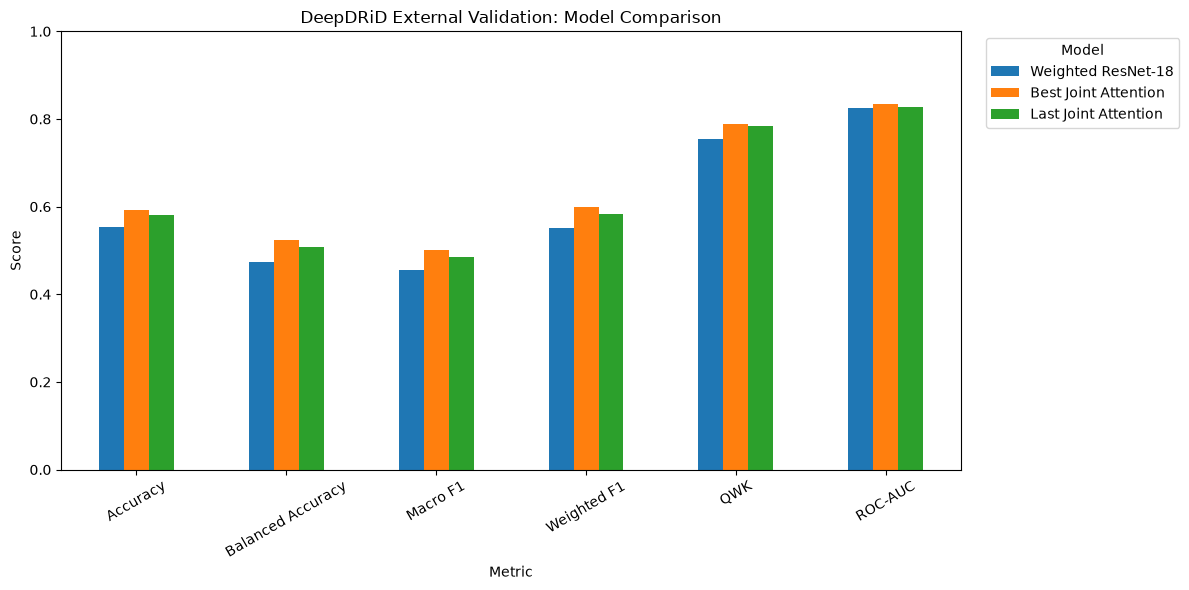

In [86]:
# ============================================================
# STEP 2: Plot model comparison
# ============================================================

plot_metrics = [
    "Accuracy",
    "Balanced Accuracy",
    "Macro F1",
    "Weighted F1",
    "QWK",
    "ROC-AUC"
]

plot_df = final_comparison[
    final_comparison["Metric"].isin(plot_metrics)
].copy()

plot_df = plot_df.set_index("Metric")

ax = plot_df.plot(
    kind="bar",
    figsize=(12, 6)
)

ax.set_ylabel("Score")
ax.set_title(
    "DeepDRiD External Validation: Model Comparison"
)

ax.set_ylim(0, 1)
ax.legend(
    title="Model",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [87]:
# ============================================================
# STEP 3: Per-class F1 comparison
# ============================================================

class_f1_comparison = pd.DataFrame({
    "Class": CLASS_NAMES,
    "Weighted ResNet-18": resnet_class_metrics["F1"].values,
    "Best Joint Attention": joint_class_metrics["F1"].values
})

display(class_f1_comparison)

,Class,Weighted ResNet-18,Best Joint Attention
0,No DR,0.712575,0.761329
1,Mild,0.202247,0.311111
2,Moderate,0.547945,0.534759
3,Severe,0.433962,0.544118
4,Proliferative DR,0.384615,0.357143


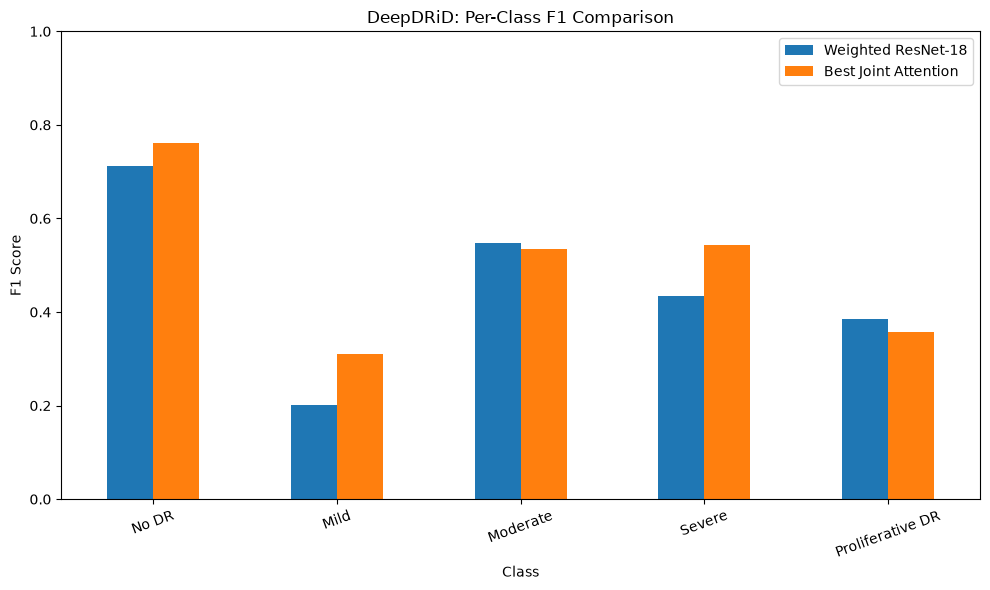

In [88]:
ax = class_f1_comparison.set_index("Class").plot(
    kind="bar",
    figsize=(10, 6)
)

ax.set_ylabel("F1 Score")
ax.set_title(
    "DeepDRiD: Per-Class F1 Comparison"
)

ax.set_ylim(0, 1)

plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [89]:
# ============================================================
# STEP 4: Quantify Joint improvement
# ============================================================

metrics_to_compare = [
    "Accuracy",
    "Balanced Accuracy",
    "Macro F1",
    "Weighted F1",
    "QWK",
    "Cohen Kappa",
    "MCC",
    "ROC-AUC"
]

improvement_rows = []

for metric in metrics_to_compare:

    r = resnet_metrics[metric]
    j = joint_metrics[metric]

    improvement_rows.append({
        "Metric": metric,
        "ResNet": r,
        "Joint": j,
        "Absolute Improvement": j - r,
        "Relative Improvement (%)": (
            (j - r) / r * 100
            if r != 0 else np.nan
        )
    })

improvement_df = pd.DataFrame(improvement_rows)

display(improvement_df)

,Metric,ResNet,Joint,Absolute Improvement,Relative Improvement (%)
0,Accuracy,0.552500,0.592500,0.040000,7.239819
1,Balanced Accuracy,0.473994,0.523216,0.049222,10.384617
2,Macro F1,0.456269,0.501692,0.045423,9.955329
3,Weighted F1,0.552260,0.600308,0.048048,8.700171
4,QWK,0.754717,0.789367,0.034650,4.591127
5,Cohen Kappa,0.378871,0.440699,0.061827,16.318844
6,MCC,0.382981,0.441833,0.058852,15.366842
7,ROC-AUC,0.824174,0.834860,0.010685,1.296505


In [90]:
# ============================================================
# STEP 5: Joint improvements by actual class
# ============================================================

joint_better = results_df[
    (~results_df["resnet_correct"]) &
    (results_df["joint_correct"])
].copy()

joint_better_summary = (
    joint_better
    .groupby("actual_label")
    .size()
    .reindex(CLASS_NAMES, fill_value=0)
    .reset_index(name="Count")
)

display(joint_better_summary)

,actual_label,Count
0,No DR,14
1,Mild,6
2,Moderate,5
3,Severe,14
4,Proliferative DR,0


In [91]:
# ============================================================
# STEP 6: ResNet improvements by actual class
# ============================================================

resnet_better = results_df[
    (results_df["resnet_correct"]) &
    (~results_df["joint_correct"])
].copy()

resnet_better_summary = (
    resnet_better
    .groupby("actual_label")
    .size()
    .reindex(CLASS_NAMES, fill_value=0)
    .reset_index(name="Count")
)

display(resnet_better_summary)

,actual_label,Count
0,No DR,7
1,Mild,1
2,Moderate,15
3,Severe,0
4,Proliferative DR,0


In [92]:
# ============================================================
# STEP 7: Attention vs correctness
# ============================================================

attention_analysis = pd.DataFrame({
    "actual": y_true_joint,
    "prediction": y_pred_joint,
    "correct": y_true_joint == y_pred_joint,
    "resnet_attention": attention_joint[:, 0],
    "efficientnet_attention": attention_joint[:, 1]
})

print("===== CORRECT PREDICTIONS =====")

display(
    attention_analysis[
        attention_analysis["correct"]
    ][
        ["resnet_attention", "efficientnet_attention"]
    ].describe()
)

print("\n===== INCORRECT PREDICTIONS =====")

display(
    attention_analysis[
        ~attention_analysis["correct"]
    ][
        ["resnet_attention", "efficientnet_attention"]
    ].describe()
)

===== CORRECT PREDICTIONS =====


,resnet_attention,efficientnet_attention
count,237.000000,237.000000
mean,0.612217,0.387782
std,0.142721,0.142721
min,0.271473,0.030006
25%,0.527788,0.298538
50%,0.612410,0.387590
75%,0.701462,0.472212
max,0.969994,0.728527



===== INCORRECT PREDICTIONS =====


,resnet_attention,efficientnet_attention
count,163.000000,163.000000
mean,0.694836,0.305164
std,0.139556,0.139556
min,0.257182,0.019344
25%,0.604049,0.226507
50%,0.691389,0.308611
75%,0.773493,0.395951
max,0.980656,0.742818


In [93]:
attention_correct_summary = (
    attention_analysis
    .groupby("correct")[
        ["resnet_attention", "efficientnet_attention"]
    ]
    .mean()
)

display(attention_correct_summary)

,resnet_attention,efficientnet_attention
correct,,
False,0.694836,0.305164
True,0.612217,0.387783


In [94]:
# ============================================================
# STEP 8: Severity-distance errors
# ============================================================

error_df = results_df.copy()

error_df["severity_error"] = (
    error_df["joint_prediction"] -
    error_df["actual"]
).abs()

major_errors = error_df[
    error_df["severity_error"] >= 2
].sort_values(
    "severity_error",
    ascending=False
)

print(
    "Joint predictions with severity error >= 2:",
    len(major_errors)
)

display(
    major_errors[
        [
            "image_path",
            "actual_label",
            "joint_prediction_label",
            "severity_error",
            "resnet_attention",
            "efficientnet_attention"
        ]
    ].head(30)
)

Joint predictions with severity error >= 2: 41


,image_path,actual_label,joint_prediction_label,severity_error,resnet_attention,efficientnet_attention
272,d:\downloads\project\Diabetic-Retinopathy-Scre...,No DR,Proliferative DR,4,0.772267,0.227733
91,d:\downloads\project\Diabetic-Retinopathy-Scre...,No DR,Severe,3,0.803358,0.196642
271,d:\downloads\project\Diabetic-Retinopathy-Scre...,No DR,Severe,3,0.759327,0.240673
26,d:\downloads\project\Diabetic-Retinopathy-Scre...,Moderate,No DR,2,0.708436,0.291564
75,d:\downloads\project\Diabetic-Retinopathy-Scre...,No DR,Moderate,2,0.658031,0.341969
85,d:\downloads\project\Diabetic-Retinopathy-Scre...,Moderate,Proliferative DR,2,0.863122,0.136877
29,d:\downloads\project\Diabetic-Retinopathy-Scre...,Moderate,No DR,2,0.569195,0.430805
33,d:\downloads\project\Diabetic-Retinopathy-Scre...,Moderate,Proliferative DR,2,0.916315,0.083685
8,d:\downloads\project\Diabetic-Retinopathy-Scre...,Moderate,Proliferative DR,2,0.705816,0.294184
90,d:\downloads\project\Diabetic-Retinopathy-Scre...,No DR,Moderate,2,0.708537,0.291463


In [95]:
# ============================================================
# STEP 9: Patient-level analysis
# ============================================================

patient_results = results_df.copy()

patient_results["patient_id"] = (
    patient_results["image_path"]
    .apply(
        lambda x: Path(x).parts[-2]
    )
)

patient_summary = (
    patient_results
    .groupby("patient_id")
    .agg(
        actual=("actual", "max"),
        joint_prediction=("joint_prediction", "max"),
        resnet_prediction=("resnet_prediction", "max")
    )
)

patient_summary["joint_correct"] = (
    patient_summary["actual"] ==
    patient_summary["joint_prediction"]
)

patient_summary["resnet_correct"] = (
    patient_summary["actual"] ==
    patient_summary["resnet_prediction"]
)

print(
    "Patients:",
    len(patient_summary)
)

print(
    "Joint patient-level accuracy:",
    patient_summary["joint_correct"].mean()
)

print(
    "ResNet patient-level accuracy:",
    patient_summary["resnet_correct"].mean()
)

Patients: 100
Joint patient-level accuracy: 0.54
ResNet patient-level accuracy: 0.44


In [96]:
# ============================================================
# STEP 10: Select Grad-CAM candidates
# ============================================================

# Correct predictions
correct_cases = results_df[
    results_df["joint_correct"]
].copy()

# Incorrect predictions
incorrect_cases = results_df[
    ~results_df["joint_correct"]
].copy()

# One/few examples from each class
selected_correct = (
    correct_cases
    .groupby("actual_label")
    .head(2)
)

print("===== CORRECT CASES =====")

display(
    selected_correct[
        [
            "image_path",
            "actual_label",
            "joint_prediction_label",
            "resnet_attention",
            "efficientnet_attention"
        ]
    ]
)

print("\n===== MAJOR ERRORS =====")

display(
    major_errors.head(10)[
        [
            "image_path",
            "actual_label",
            "joint_prediction_label",
            "severity_error",
            "resnet_attention",
            "efficientnet_attention"
        ]
    ]
)

===== CORRECT CASES =====


,image_path,actual_label,joint_prediction_label,resnet_attention,efficientnet_attention
0,d:\downloads\project\Diabetic-Retinopathy-Scre...,Severe,Severe,0.757853,0.242147
1,d:\downloads\project\Diabetic-Retinopathy-Scre...,Severe,Severe,0.791786,0.208214
2,d:\downloads\project\Diabetic-Retinopathy-Scre...,Proliferative DR,Proliferative DR,0.808440,0.191560
3,d:\downloads\project\Diabetic-Retinopathy-Scre...,Proliferative DR,Proliferative DR,0.843706,0.156294
16,d:\downloads\project\Diabetic-Retinopathy-Scre...,Moderate,Moderate,0.661086,0.338914
21,d:\downloads\project\Diabetic-Retinopathy-Scre...,No DR,No DR,0.560317,0.439683
22,d:\downloads\project\Diabetic-Retinopathy-Scre...,No DR,No DR,0.312129,0.687871
28,d:\downloads\project\Diabetic-Retinopathy-Scre...,Moderate,Moderate,0.604552,0.395448
131,d:\downloads\project\Diabetic-Retinopathy-Scre...,Mild,Mild,0.653090,0.346910
162,d:\downloads\project\Diabetic-Retinopathy-Scre...,Mild,Mild,0.665991,0.334009



===== MAJOR ERRORS =====


,image_path,actual_label,joint_prediction_label,severity_error,resnet_attention,efficientnet_attention
272,d:\downloads\project\Diabetic-Retinopathy-Scre...,No DR,Proliferative DR,4,0.772267,0.227733
91,d:\downloads\project\Diabetic-Retinopathy-Scre...,No DR,Severe,3,0.803358,0.196642
271,d:\downloads\project\Diabetic-Retinopathy-Scre...,No DR,Severe,3,0.759327,0.240673
26,d:\downloads\project\Diabetic-Retinopathy-Scre...,Moderate,No DR,2,0.708436,0.291564
75,d:\downloads\project\Diabetic-Retinopathy-Scre...,No DR,Moderate,2,0.658031,0.341969
85,d:\downloads\project\Diabetic-Retinopathy-Scre...,Moderate,Proliferative DR,2,0.863122,0.136877
29,d:\downloads\project\Diabetic-Retinopathy-Scre...,Moderate,No DR,2,0.569195,0.430805
33,d:\downloads\project\Diabetic-Retinopathy-Scre...,Moderate,Proliferative DR,2,0.916315,0.083685
8,d:\downloads\project\Diabetic-Retinopathy-Scre...,Moderate,Proliferative DR,2,0.705816,0.294184
90,d:\downloads\project\Diabetic-Retinopathy-Scre...,No DR,Moderate,2,0.708537,0.291463


In [97]:
# ============================================================
# STEP 11: Save Grad-CAM candidate list
# ============================================================

gradcam_candidates = pd.concat([
    selected_correct,
    major_errors.head(10)
]).drop_duplicates(
    subset=["image_path"]
)

gradcam_candidates.to_csv(
    analysis_dir / "gradcam_candidates.csv",
    index=False
)

print(
    "Saved:",
    analysis_dir / "gradcam_candidates.csv"
)

Saved: D:\downloads\project\Diabetic-Retinopathy-Screening-Project\data\external\deepdrid\evaluation_results\analysis\gradcam_candidates.csv


In [98]:
# ============================================================
# STEP 1: Reload BEST Joint checkpoint for Grad-CAM
# ============================================================

best_joint_checkpoint = torch.load(
    BEST_JOINT_CHECKPOINT,
    map_location=device,
    weights_only=False
)

joint_model.load_state_dict(
    best_joint_checkpoint["model_state_dict"]
)

joint_model = joint_model.to(device)
joint_model.eval()

print("✅ Best Joint model loaded for Grad-CAM")

✅ Best Joint model loaded for Grad-CAM


In [99]:
# ============================================================
# STEP 2: Identify target layers
# ============================================================

resnet_target_layer = (
    joint_model
    .resnet_features[-2][-1]
    .conv2
)

efficientnet_target_layer = (
    joint_model
    .efficientnet_features[-1]
)

print("ResNet target layer:")
print(resnet_target_layer)

print("\nEfficientNet target layer:")
print(efficientnet_target_layer)

ResNet target layer:
Conv2d(512, 512, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)

EfficientNet target layer:
Conv2dNormActivation(
  (0): Conv2d(320, 1280, kernel_size=(1, 1), stride=(1, 1), bias=False)
  (1): BatchNorm2d(1280, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (2): SiLU(inplace=True)
)


In [100]:
# ============================================================
# STEP 3: Generic Grad-CAM implementation
# ============================================================

def generate_gradcam(
    model,
    image_tensor,
    target_layer,
    target_class=None
):
    """
    Generate Grad-CAM for one branch of the Joint model.

    Returns:
        cam            : H x W numpy array
        predicted_cls  : predicted class
        target_cls     : class used for Grad-CAM
        probabilities  : 5-class probabilities
    """

    model.eval()

    activations = []
    gradients = []

    # --------------------------------------------------------
    # Forward hook
    # --------------------------------------------------------

    def forward_hook(module, input, output):

        activations.append(
            output.detach()
        )

    # --------------------------------------------------------
    # Backward hook
    # --------------------------------------------------------

    def backward_hook(module, grad_input, grad_output):

        gradients.append(
            grad_output[0].detach()
        )

    forward_handle = target_layer.register_forward_hook(
        forward_hook
    )

    backward_handle = target_layer.register_full_backward_hook(
        backward_hook
    )

    try:

        # ----------------------------------------------------
        # Forward pass
        # ----------------------------------------------------

        model.zero_grad(set_to_none=True)

        image_tensor = image_tensor.to(device)

        logits, attention = model(
            image_tensor
        )

        probabilities = torch.softmax(
            logits,
            dim=1
        )

        predicted_cls = int(
            torch.argmax(
                probabilities,
                dim=1
            ).item()
        )

        # Use predicted class unless another class is specified
        if target_class is None:
            target_cls = predicted_cls
        else:
            target_cls = int(target_class)

        # ----------------------------------------------------
        # Backward pass
        # ----------------------------------------------------

        score = logits[:, target_cls].sum()

        score.backward()

        # ----------------------------------------------------
        # Get activations and gradients
        # ----------------------------------------------------

        activation = activations[0]
        gradient = gradients[0]

        # ----------------------------------------------------
        # Grad-CAM weights
        # ----------------------------------------------------

        weights = gradient.mean(
            dim=(2, 3),
            keepdim=True
        )

        cam = (
            weights * activation
        ).sum(
            dim=1
        )

        # ReLU
        cam = torch.relu(cam)

        # Remove batch dimension
        cam = cam[0].cpu().numpy()

        # ----------------------------------------------------
        # Normalize CAM
        # ----------------------------------------------------

        cam_min = cam.min()
        cam_max = cam.max()

        if cam_max - cam_min > 1e-8:

            cam = (
                cam - cam_min
            ) / (
                cam_max - cam_min
            )

        else:

            cam = np.zeros_like(cam)

    finally:

        # Always remove hooks
        forward_handle.remove()
        backward_handle.remove()

        model.zero_grad(set_to_none=True)

    return (
        cam,
        predicted_cls,
        target_cls,
        probabilities[0].detach().cpu().numpy()
    )

In [101]:
# ============================================================
# STEP 4: Select one test image
# ============================================================

test_row = joint_better[
    joint_better["actual_label"] == "Severe"
].iloc[0]

test_path = test_row["image_path"]

print("Image:")
print(test_path)

print("Actual:")
print(test_row["actual_label"])

print("ResNet prediction:")
print(test_row["resnet_prediction_label"])

print("Joint prediction:")
print(test_row["joint_prediction_label"])

Image:
d:\downloads\project\Diabetic-Retinopathy-Screening-Project\data\external\deepdrid\deepdrdoc-DeepDRiD-56d8af7\regular_fundus_images\regular-fundus-validation\Images\296\296_r1.jpg
Actual:
Severe
ResNet prediction:
Moderate
Joint prediction:
Severe


In [102]:
# ============================================================
# STEP 5: Load and preprocess image
# ============================================================

from PIL import Image
import torchvision.transforms as transforms

image = Image.open(
    test_path
).convert("RGB")

image_tensor = eval_transform(
    image
).unsqueeze(0)

print("Image tensor:")
print(image_tensor.shape)

Image tensor:
torch.Size([1, 3, 224, 224])


In [103]:
# ============================================================
# STEP 6: Generate ResNet + EfficientNet Grad-CAM
# ============================================================

resnet_cam, pred_class, target_class, probabilities = (
    generate_gradcam(
        joint_model,
        image_tensor,
        resnet_target_layer
    )
)

efficientnet_cam, _, _, _ = (
    generate_gradcam(
        joint_model,
        image_tensor,
        efficientnet_target_layer,
        target_class=target_class
    )
)

print("Predicted class:")
print(CLASS_NAMES[pred_class])

print("\nTarget class:")
print(CLASS_NAMES[target_class])

print("\nProbabilities:")

for i, prob in enumerate(probabilities):

    print(
        f"{CLASS_NAMES[i]:20s}: {prob:.4f}"
    )

print("\nResNet CAM shape:")
print(resnet_cam.shape)

print("\nEfficientNet CAM shape:")
print(efficientnet_cam.shape)

Predicted class:
Severe

Target class:
Severe

Probabilities:
No DR               : 0.0038
Mild                : 0.0047
Moderate            : 0.1401
Severe              : 0.7980
Proliferative DR    : 0.0534

ResNet CAM shape:
(7, 7)

EfficientNet CAM shape:
(7, 7)


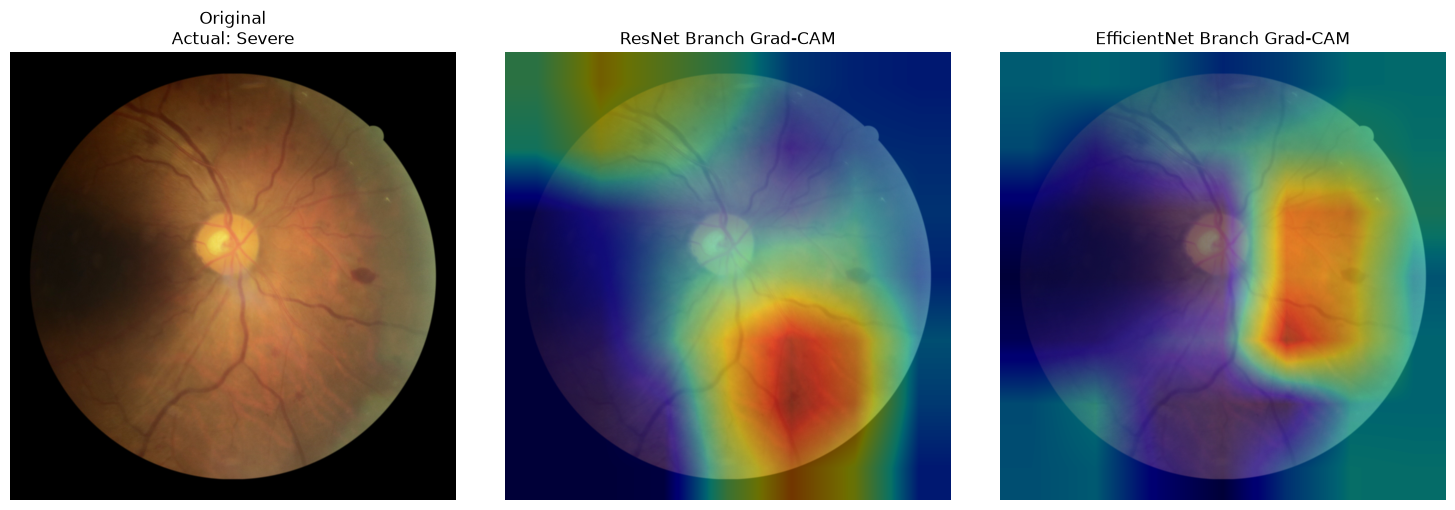

In [104]:
# ============================================================
# STEP 7: Grad-CAM visualization
# ============================================================

import matplotlib.pyplot as plt
import torch.nn.functional as F

def overlay_cam(
    image,
    cam,
    alpha=0.45
):

    # Resize CAM to image size
    cam_tensor = torch.tensor(
        cam
    ).unsqueeze(0).unsqueeze(0)

    cam_resized = F.interpolate(
        cam_tensor,
        size=(image.height, image.width),
        mode="bilinear",
        align_corners=False
    )[0, 0].numpy()

    # Normalize
    cam_resized = (
        cam_resized - cam_resized.min()
    ) / (
        cam_resized.max() -
        cam_resized.min() +
        1e-8
    )

    # Plot CAM overlay
    plt.imshow(image)
    plt.imshow(
        cam_resized,
        cmap="jet",
        alpha=alpha
    )
    plt.axis("off")


plt.figure(figsize=(15, 5))

# Original
plt.subplot(1, 3, 1)
plt.imshow(image)
plt.axis("off")
plt.title(
    f"Original\nActual: {CLASS_NAMES[int(test_row['actual'])]}"
)

# ResNet
plt.subplot(1, 3, 2)
overlay_cam(
    image,
    resnet_cam
)
plt.title("ResNet Branch Grad-CAM")

# EfficientNet
plt.subplot(1, 3, 3)
overlay_cam(
    image,
    efficientnet_cam
)
plt.title("EfficientNet Branch Grad-CAM")

plt.tight_layout()
plt.show()

In [105]:
# ============================================================
# STEP 8: Select Grad-CAM examples
# ============================================================

selected_cases = []

# ------------------------------------------------------------
# 1. One correct case from each class
# ------------------------------------------------------------

for cls in CLASS_NAMES:

    candidates = results_df[
        (results_df["actual_label"] == cls) &
        (results_df["joint_correct"])
    ]

    if len(candidates) > 0:

        selected_cases.append(
            candidates.iloc[0]
        )


# ------------------------------------------------------------
# 2. Joint improvements
# ------------------------------------------------------------

for cls in [
    "Mild",
    "Severe"
]:

    candidates = joint_better[
        joint_better["actual_label"] == cls
    ]

    if len(candidates) > 0:

        selected_cases.append(
            candidates.iloc[0]
        )


# ------------------------------------------------------------
# 3. Major errors
# ------------------------------------------------------------

for _, row in major_errors.head(3).iterrows():

    selected_cases.append(row)


gradcam_df = pd.DataFrame(
    selected_cases
).drop_duplicates(
    subset=["image_path"]
)

print(
    "Selected Grad-CAM cases:",
    len(gradcam_df)
)

display(
    gradcam_df[
        [
            "image_path",
            "actual_label",
            "resnet_prediction_label",
            "joint_prediction_label"
        ]
    ]
)

Selected Grad-CAM cases: 9


,image_path,actual_label,resnet_prediction_label,joint_prediction_label
21,d:\downloads\project\Diabetic-Retinopathy-Scre...,No DR,No DR,No DR
131,d:\downloads\project\Diabetic-Retinopathy-Scre...,Mild,No DR,Mild
16,d:\downloads\project\Diabetic-Retinopathy-Scre...,Moderate,Moderate,Moderate
0,d:\downloads\project\Diabetic-Retinopathy-Scre...,Severe,Severe,Severe
2,d:\downloads\project\Diabetic-Retinopathy-Scre...,Proliferative DR,Proliferative DR,Proliferative DR
18,d:\downloads\project\Diabetic-Retinopathy-Scre...,Severe,Moderate,Severe
272,d:\downloads\project\Diabetic-Retinopathy-Scre...,No DR,Moderate,Proliferative DR
91,d:\downloads\project\Diabetic-Retinopathy-Scre...,No DR,No DR,Severe
271,d:\downloads\project\Diabetic-Retinopathy-Scre...,No DR,No DR,Severe


In [106]:
# ============================================================
# STEP 9: Generate Grad-CAM results
# ============================================================

gradcam_results = []

for idx, row in gradcam_df.iterrows():

    path = row["image_path"]

    image = Image.open(
        path
    ).convert("RGB")

    image_tensor = eval_transform(
        image
    ).unsqueeze(0)

    # ResNet branch
    res_cam, pred_cls, target_cls, probs = (
        generate_gradcam(
            joint_model,
            image_tensor,
            resnet_target_layer
        )
    )

    # EfficientNet branch
    eff_cam, _, _, _ = (
        generate_gradcam(
            joint_model,
            image_tensor,
            efficientnet_target_layer,
            target_class=target_cls
        )
    )

    gradcam_results.append({
        "image_path": path,
        "actual": int(row["actual"]),
        "actual_label": row["actual_label"],
        "prediction": pred_cls,
        "prediction_label": CLASS_NAMES[pred_cls],
        "resnet_cam": res_cam,
        "efficientnet_cam": eff_cam
    })

print(
    "✅ Grad-CAM generated for",
    len(gradcam_results),
    "images"
)

✅ Grad-CAM generated for 9 images


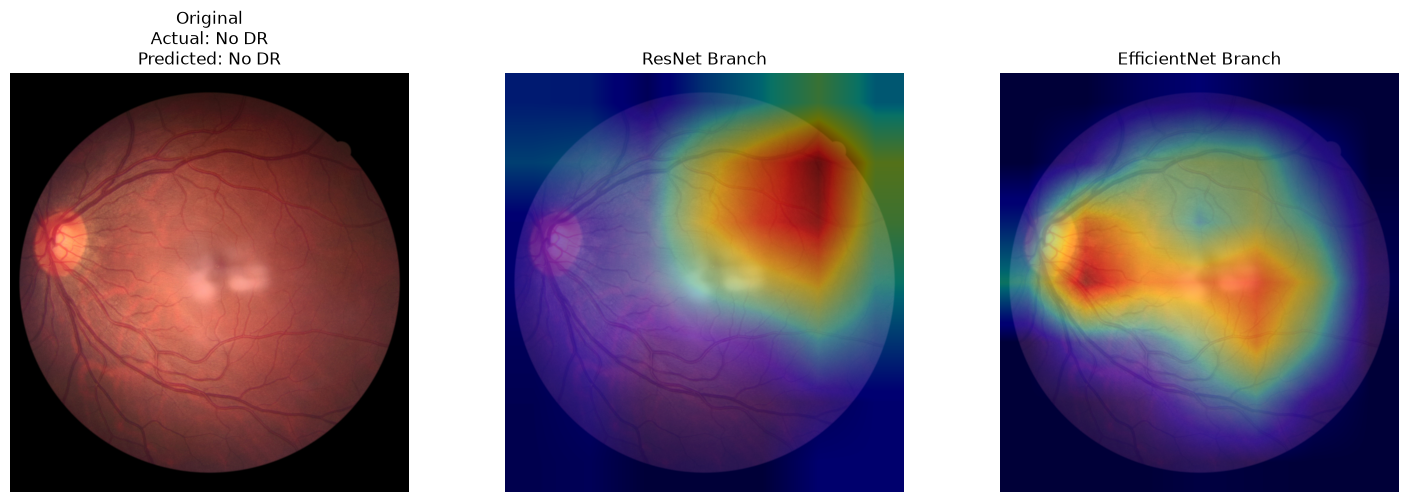

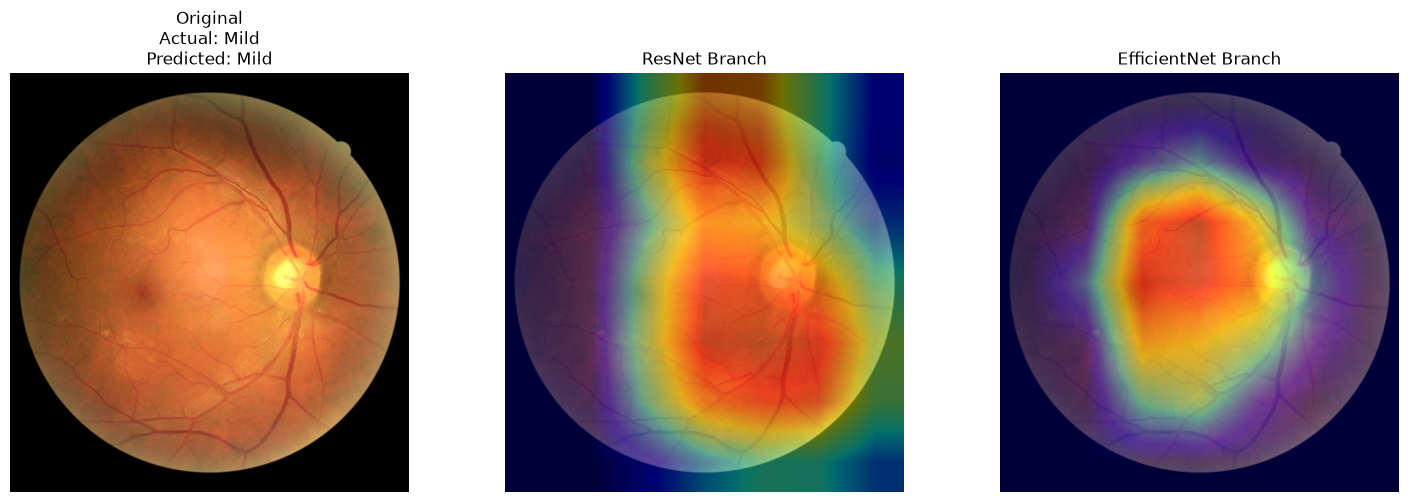

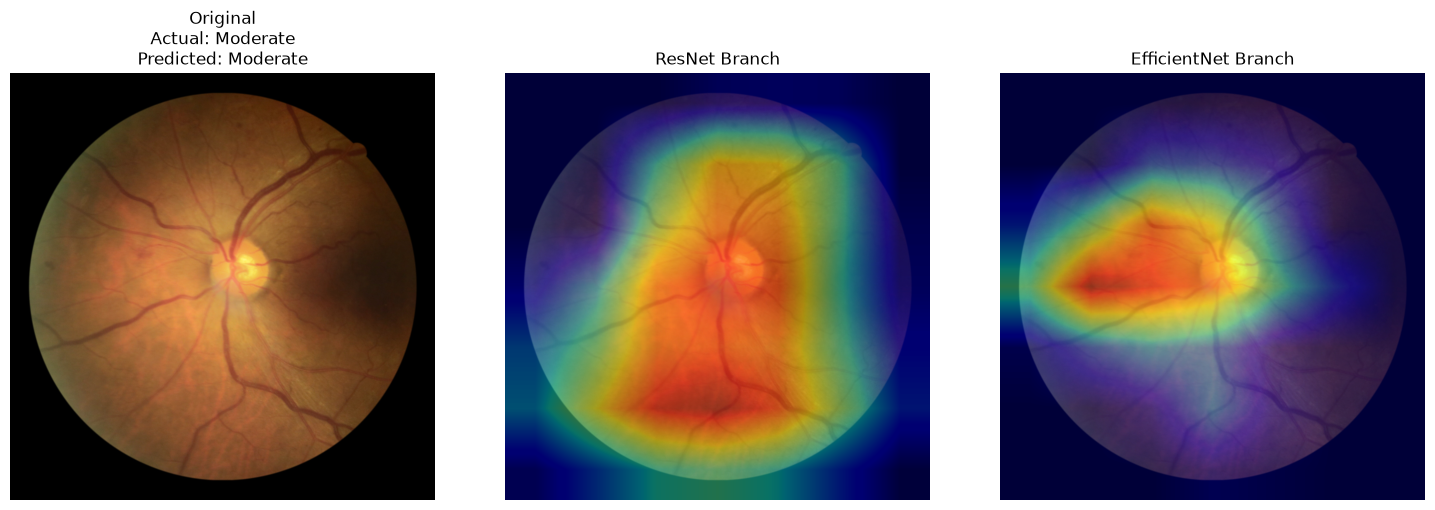

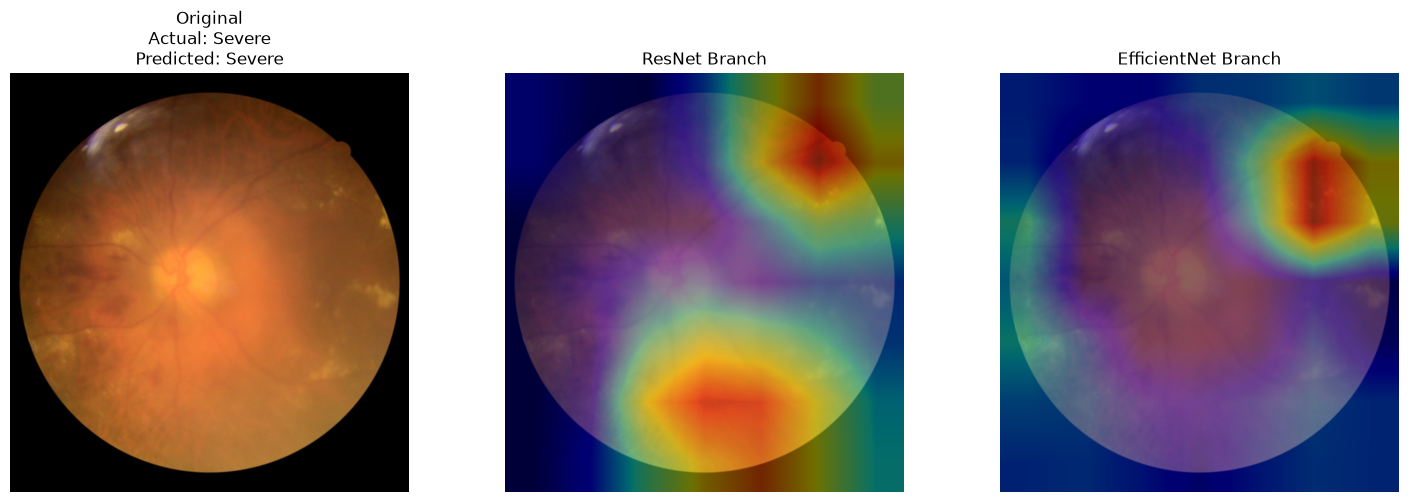

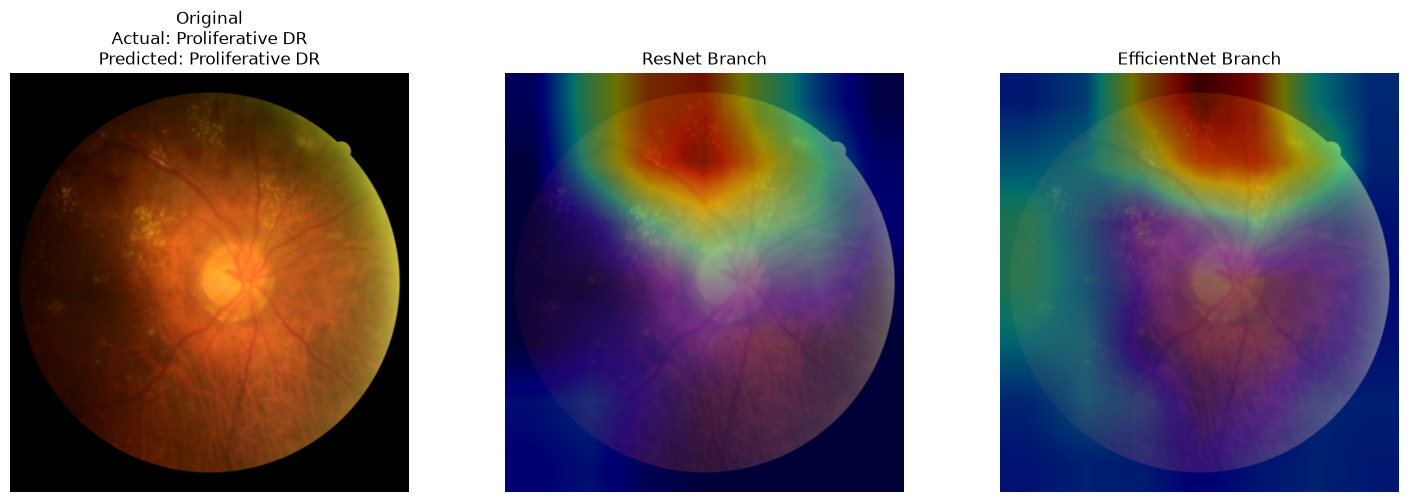

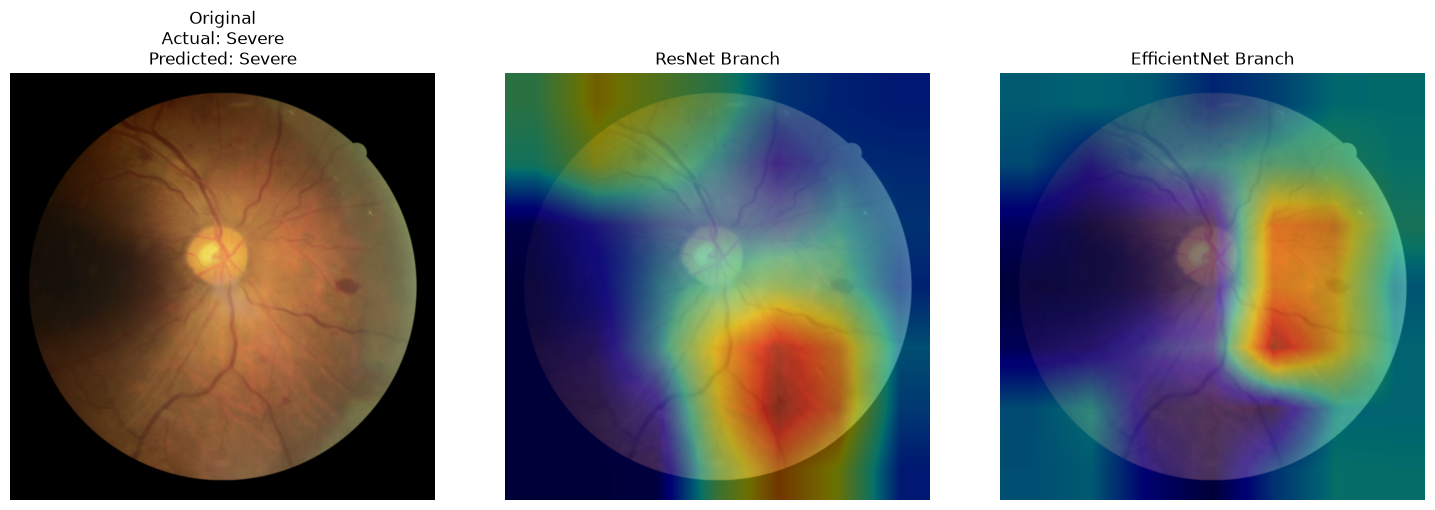

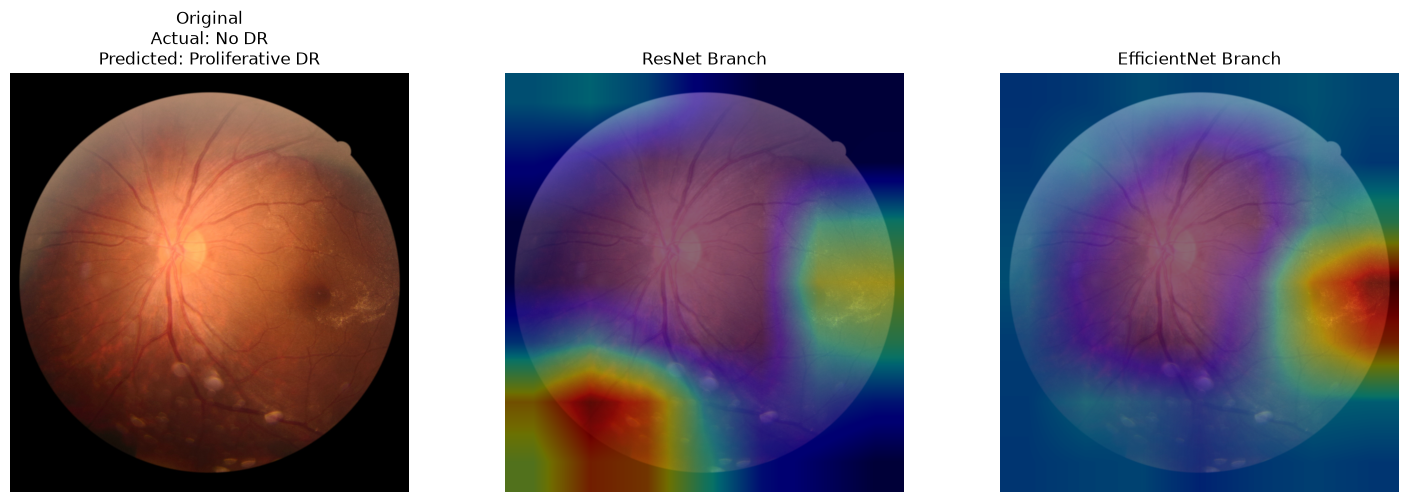

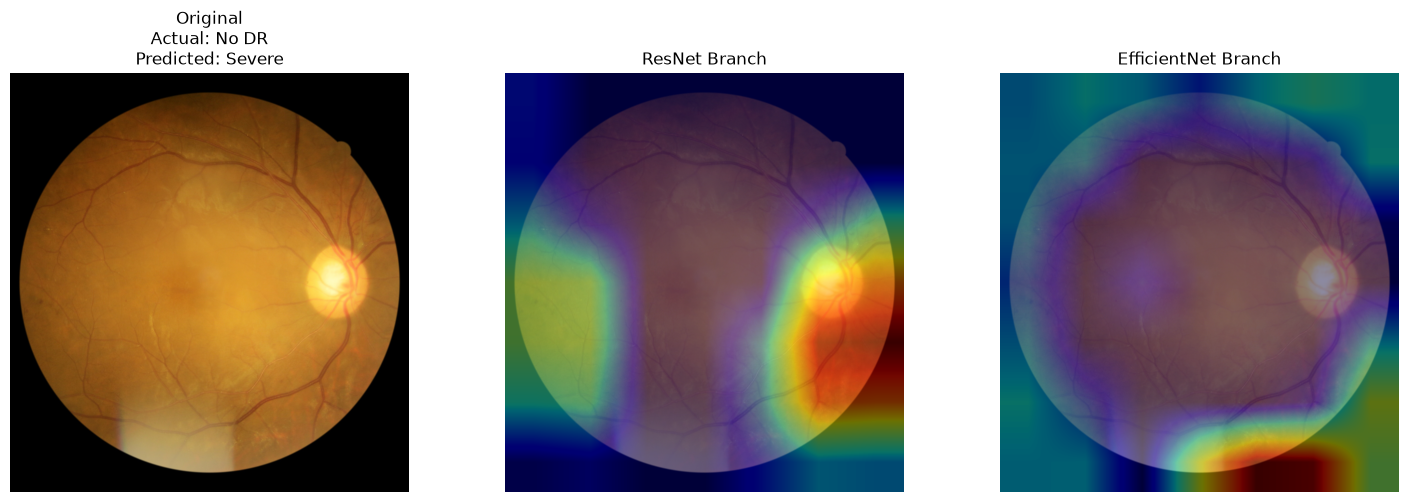

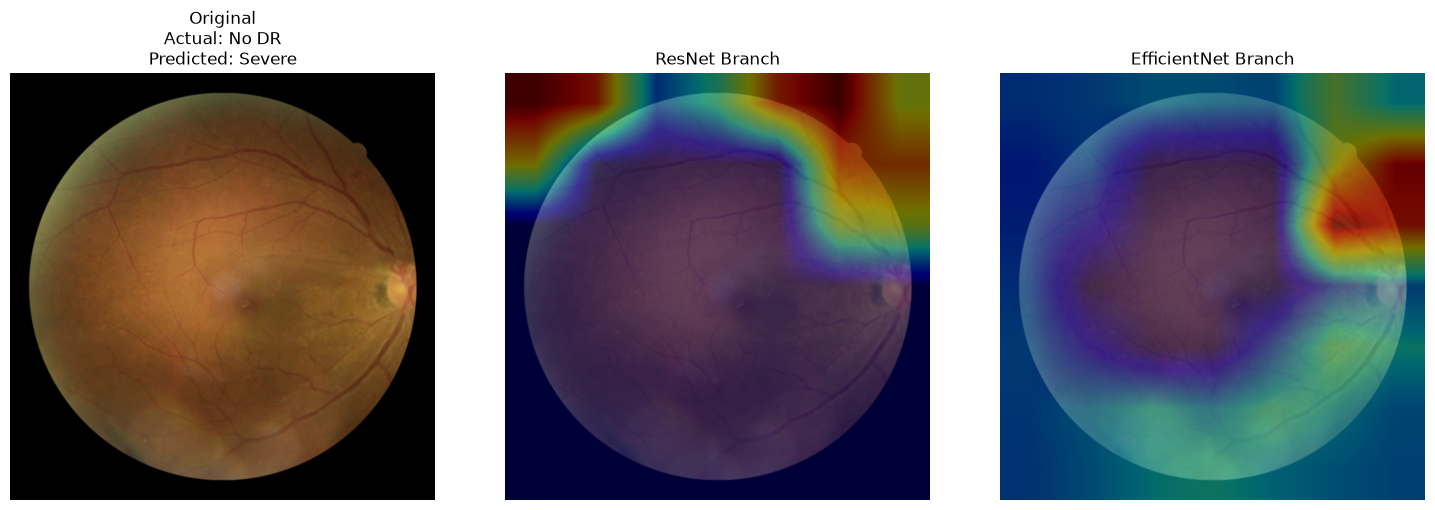

In [107]:
# ============================================================
# STEP 10: Display Grad-CAM cases
# ============================================================

def show_gradcam_case(result):

    image = Image.open(
        result["image_path"]
    ).convert("RGB")

    plt.figure(figsize=(15, 5))

    # Original
    plt.subplot(1, 3, 1)

    plt.imshow(image)

    plt.title(
        f"Original\n"
        f"Actual: {result['actual_label']}\n"
        f"Predicted: {result['prediction_label']}"
    )

    plt.axis("off")

    # ResNet
    plt.subplot(1, 3, 2)

    overlay_cam(
        image,
        result["resnet_cam"]
    )

    plt.title(
        "ResNet Branch"
    )

    # EfficientNet
    plt.subplot(1, 3, 3)

    overlay_cam(
        image,
        result["efficientnet_cam"]
    )

    plt.title(
        "EfficientNet Branch"
    )

    plt.tight_layout()

    plt.show()


for result in gradcam_results:

    show_gradcam_case(result)

In [108]:
# ============================================================
# STEP 11: Save Grad-CAM visualizations
# ============================================================

gradcam_output_dir = (
    analysis_dir / "gradcam"
)

gradcam_output_dir.mkdir(
    parents=True,
    exist_ok=True
)

for i, result in enumerate(gradcam_results):

    image = Image.open(
        result["image_path"]
    ).convert("RGB")

    plt.figure(figsize=(15, 5))

    # Original
    plt.subplot(1, 3, 1)

    plt.imshow(image)

    plt.title(
        f"Original\n"
        f"Actual: {result['actual_label']}\n"
        f"Predicted: {result['prediction_label']}"
    )

    plt.axis("off")

    # ResNet
    plt.subplot(1, 3, 2)

    overlay_cam(
        image,
        result["resnet_cam"]
    )

    plt.title(
        "ResNet Branch Grad-CAM"
    )

    # EfficientNet
    plt.subplot(1, 3, 3)

    overlay_cam(
        image,
        result["efficientnet_cam"]
    )

    plt.title(
        "EfficientNet Branch Grad-CAM"
    )

    plt.tight_layout()

    output_file = (
        gradcam_output_dir /
        f"case_{i+1:02d}.png"
    )

    plt.savefig(
        output_file,
        dpi=200,
        bbox_inches="tight"
    )

    plt.close()

print(
    "✅ Grad-CAM images saved to:"
)

print(gradcam_output_dir)

✅ Grad-CAM images saved to:
D:\downloads\project\Diabetic-Retinopathy-Screening-Project\data\external\deepdrid\evaluation_results\analysis\gradcam


In [109]:
# ============================================================
# STEP 12: Grad-CAM summary
# ============================================================

gradcam_summary = pd.DataFrame([
    {
        "image_path": r["image_path"],
        "actual": r["actual"],
        "actual_label": r["actual_label"],
        "prediction": r["prediction"],
        "prediction_label": r["prediction_label"]
    }
    for r in gradcam_results
])

gradcam_summary.to_csv(
    analysis_dir /
    "gradcam_summary.csv",
    index=False
)

display(gradcam_summary)

,image_path,actual,actual_label,prediction,prediction_label
0,d:\downloads\project\Diabetic-Retinopathy-Scre...,0,No DR,0,No DR
1,d:\downloads\project\Diabetic-Retinopathy-Scre...,1,Mild,1,Mild
2,d:\downloads\project\Diabetic-Retinopathy-Scre...,2,Moderate,2,Moderate
3,d:\downloads\project\Diabetic-Retinopathy-Scre...,3,Severe,3,Severe
4,d:\downloads\project\Diabetic-Retinopathy-Scre...,4,Proliferative DR,4,Proliferative DR
5,d:\downloads\project\Diabetic-Retinopathy-Scre...,3,Severe,3,Severe
6,d:\downloads\project\Diabetic-Retinopathy-Scre...,0,No DR,4,Proliferative DR
7,d:\downloads\project\Diabetic-Retinopathy-Scre...,0,No DR,3,Severe
8,d:\downloads\project\Diabetic-Retinopathy-Scre...,0,No DR,3,Severe


In [110]:
# ============================================================
# FINAL GRAD-CAM FIGURE
# ============================================================

# Pick 6 cases manually from gradcam_results
# based on actual/prediction combination

final_cases = []

# Correct examples
for actual_class in [
    "No DR",
    "Mild",
    "Moderate",
    "Proliferative DR"
]:
    
    candidates = [
        r for r in gradcam_results
        if r["actual_label"] == actual_class
        and r["prediction_label"] == actual_class
    ]
    
    if candidates:
        final_cases.append(candidates[0])


# Severe case recovered by Joint
severe_recovery = [
    r for r in gradcam_results
    if r["actual_label"] == "Severe"
    and r["prediction_label"] == "Severe"
]

if severe_recovery:
    final_cases.append(severe_recovery[0])


# Add one error
error_cases = [
    r for r in gradcam_results
    if r["actual_label"] == "No DR"
    and r["prediction_label"] != "No DR"
]

if error_cases:
    final_cases.append(error_cases[0])


print("Final Grad-CAM cases:", len(final_cases))

Final Grad-CAM cases: 6


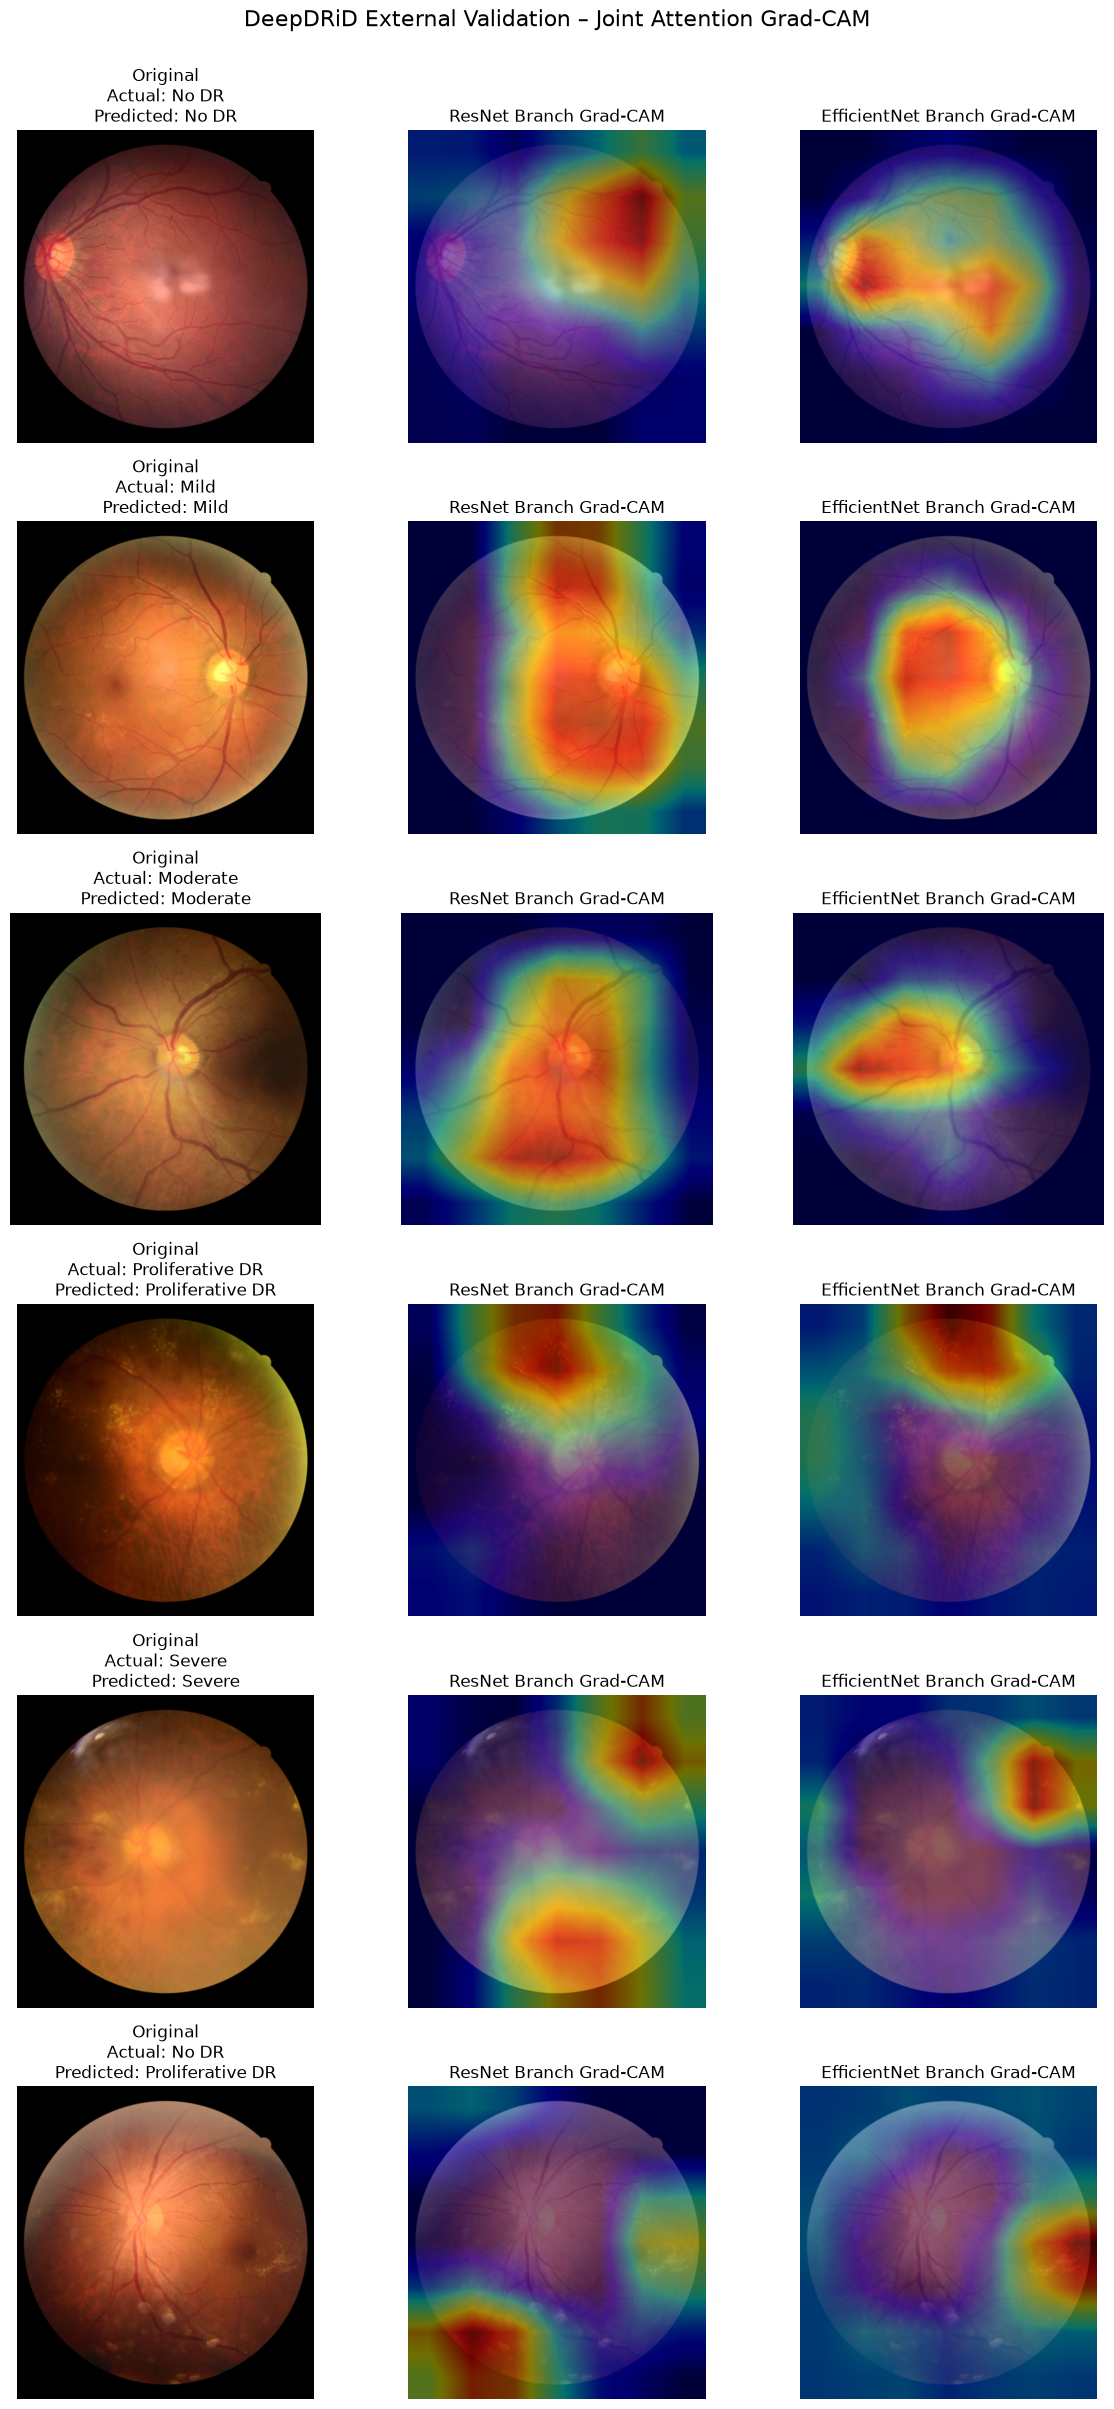

Saved:
D:\downloads\project\Diabetic-Retinopathy-Screening-Project\data\external\deepdrid\evaluation_results\analysis\final_deepdrid_gradcam_figure.png


In [111]:
# ============================================================
# CREATE FINAL 6-CASE GRAD-CAM FIGURE
# ============================================================

fig, axes = plt.subplots(
    len(final_cases),
    3,
    figsize=(12, 4 * len(final_cases))
)

if len(final_cases) == 1:
    axes = np.expand_dims(axes, axis=0)


for i, result in enumerate(final_cases):

    image = Image.open(
        result["image_path"]
    ).convert("RGB")

    # --------------------------------------------------------
    # Original
    # --------------------------------------------------------

    axes[i, 0].imshow(image)

    axes[i, 0].set_title(
        f"Original\n"
        f"Actual: {result['actual_label']}\n"
        f"Predicted: {result['prediction_label']}"
    )

    axes[i, 0].axis("off")


    # --------------------------------------------------------
    # ResNet Grad-CAM
    # --------------------------------------------------------

    cam_tensor = torch.tensor(
        result["resnet_cam"]
    ).unsqueeze(0).unsqueeze(0)

    cam_resized = F.interpolate(
        cam_tensor,
        size=(image.height, image.width),
        mode="bilinear",
        align_corners=False
    )[0, 0].numpy()

    axes[i, 1].imshow(image)

    axes[i, 1].imshow(
        cam_resized,
        cmap="jet",
        alpha=0.45
    )

    axes[i, 1].set_title(
        "ResNet Branch Grad-CAM"
    )

    axes[i, 1].axis("off")


    # --------------------------------------------------------
    # EfficientNet Grad-CAM
    # --------------------------------------------------------

    cam_tensor = torch.tensor(
        result["efficientnet_cam"]
    ).unsqueeze(0).unsqueeze(0)

    cam_resized = F.interpolate(
        cam_tensor,
        size=(image.height, image.width),
        mode="bilinear",
        align_corners=False
    )[0, 0].numpy()

    axes[i, 2].imshow(image)

    axes[i, 2].imshow(
        cam_resized,
        cmap="jet",
        alpha=0.45
    )

    axes[i, 2].set_title(
        "EfficientNet Branch Grad-CAM"
    )

    axes[i, 2].axis("off")


plt.suptitle(
    "DeepDRiD External Validation – Joint Attention Grad-CAM",
    fontsize=16,
    y=1.002
)

plt.tight_layout()

final_gradcam_path = (
    analysis_dir /
    "final_deepdrid_gradcam_figure.png"
)

plt.savefig(
    final_gradcam_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:")
print(final_gradcam_path)

In [112]:
# ============================================================
# FINAL RESULTS TABLE
# ============================================================

final_results_table = pd.DataFrame({

    "Model": [
        "Weighted ResNet-18",
        "Best Joint Attention",
        "Last Joint Attention"
    ],

    "Accuracy": [
        resnet_metrics["Accuracy"],
        joint_metrics["Accuracy"],
        last_joint_metrics["Accuracy"]
    ],

    "Balanced Accuracy": [
        resnet_metrics["Balanced Accuracy"],
        joint_metrics["Balanced Accuracy"],
        last_joint_metrics["Balanced Accuracy"]
    ],

    "Macro F1": [
        resnet_metrics["Macro F1"],
        joint_metrics["Macro F1"],
        last_joint_metrics["Macro F1"]
    ],

    "Weighted F1": [
        resnet_metrics["Weighted F1"],
        joint_metrics["Weighted F1"],
        last_joint_metrics["Weighted F1"]
    ],

    "QWK": [
        resnet_metrics["QWK"],
        joint_metrics["QWK"],
        last_joint_metrics["QWK"]
    ],

    "Cohen Kappa": [
        resnet_metrics["Cohen Kappa"],
        joint_metrics["Cohen Kappa"],
        last_joint_metrics["Cohen Kappa"]
    ],

    "MCC": [
        resnet_metrics["MCC"],
        joint_metrics["MCC"],
        last_joint_metrics["MCC"]
    ],

    "ROC-AUC": [
        resnet_metrics["ROC-AUC"],
        joint_metrics["ROC-AUC"],
        last_joint_metrics["ROC-AUC"]
    ],

    "Log Loss": [
        resnet_metrics["Log Loss"],
        joint_metrics["Log Loss"],
        last_joint_metrics["Log Loss"]
    ]
})

display(
    final_results_table.style.format(
        {
            "Accuracy": "{:.4f}",
            "Balanced Accuracy": "{:.4f}",
            "Macro F1": "{:.4f}",
            "Weighted F1": "{:.4f}",
            "QWK": "{:.4f}",
            "Cohen Kappa": "{:.4f}",
            "MCC": "{:.4f}",
            "ROC-AUC": "{:.4f}",
            "Log Loss": "{:.4f}"
        }
    )
)

,Model,Accuracy,Balanced Accuracy,Macro F1,Weighted F1,QWK,Cohen Kappa,MCC,ROC-AUC,Log Loss
0,Weighted ResNet-18,0.5525,0.4740,0.4563,0.5523,0.7547,0.3789,0.3830,0.8242,1.6928
1,Best Joint Attention,0.5925,0.5232,0.5017,0.6003,0.7894,0.4407,0.4418,0.8349,1.0575
2,Last Joint Attention,0.5800,0.5088,0.4842,0.5840,0.7844,0.4213,0.4227,0.8280,1.2450


In [114]:
# ============================================================
# FINAL DEEPDRID SUMMARY
# ============================================================

summary = {
    "External Dataset": "DeepDRiD Regular Fundus Set-B",
    "Number of Images": 400,
    "Number of Patients": 100,
    "Number of Classes": 5,

    "ResNet Accuracy": resnet_metrics["Accuracy"],
    "Joint Accuracy": joint_metrics["Accuracy"],

    "ResNet Macro F1": resnet_metrics["Macro F1"],
    "Joint Macro F1": joint_metrics["Macro F1"],

    "ResNet QWK": resnet_metrics["QWK"],
    "Joint QWK": joint_metrics["QWK"],

    "ResNet ROC-AUC": resnet_metrics["ROC-AUC"],
    "Joint ROC-AUC": joint_metrics["ROC-AUC"],

    "Joint Improvements": len(joint_better),
    "ResNet Improvements": len(resnet_better),

    "Mean ResNet Attention": attention_df[
        "ResNet_Attention"
    ].mean(),

    "Mean EfficientNet Attention": attention_df[
        "EfficientNet_Attention"
    ].mean()
}

summary_df = pd.DataFrame(
    summary.items(),
    columns=["Item", "Value"]
)

display(summary_df)

# Save
summary_df.to_csv(
    OUTPUT_DIR / "FINAL_DEEPDRID_SUMMARY.csv",
    index=False
)

print("\n✅ Summary saved successfully:")
print(OUTPUT_DIR / "FINAL_DEEPDRID_SUMMARY.csv")

,Item,Value
0,External Dataset,DeepDRiD Regular Fundus Set-B
1,Number of Images,400
2,Number of Patients,100
3,Number of Classes,5
4,ResNet Accuracy,0.5525
5,Joint Accuracy,0.5925
6,ResNet Macro F1,0.456269
7,Joint Macro F1,0.501692
8,ResNet QWK,0.754717
9,Joint QWK,0.789367



✅ Summary saved successfully:
D:\downloads\project\Diabetic-Retinopathy-Screening-Project\data\external\deepdrid\evaluation_results\FINAL_DEEPDRID_SUMMARY.csv
